## Feature reduction

**Question**: how much can we shrink the NLP feature set without losing OOD quality, and what do we pay in latency/size?

- Baseline: 130 features, models from `models.ipynb` (`models/*.pkl`, `model_artifact.json`)
- Study: baseline → S1 (dedupe) → S2 (top-53) → S3 (group ablations) → K-sweep × 4 bases → 5-fold CV
- Primary metric: OOD TPR@fpr=1e-3 (FPR-constrained deployment); AP is secondary
- Selection rule and viability gate are pre-registered in the config cell (avoid post-hoc tuning)
- Artifacts: `optimization_summary.csv`, `model_artifact_v2.json`, `optimized_features.json`, `{name}_optimized.pkl`

### Section 0. Setup

In [41]:
import gc
import io
import json
import os
import time
import warnings
from copy import deepcopy
from numbers import Integral
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import wilcoxon
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

In [42]:
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning:sklearn.utils.parallel"
sns.set_style("whitegrid")

In [43]:
SEED = 42
np.random.seed(SEED)

BASE_DIR = Path.cwd()
PATHS = {
    "processed": BASE_DIR / "dataset_processed.csv",
    "splits": BASE_DIR / "split_indices.npz",
    "cv_folds": BASE_DIR / "cv_fold_indices.npz",
    "artifact": BASE_DIR / "model_artifact.json",
    "models_dir": BASE_DIR / "models",
    "plots_dir": BASE_DIR / "plots",
}
PATHS["plots_dir"].mkdir(exist_ok=True)

TARGET_FPR = 1e-3

# Selection rule
SELECTION_TOLERANCE_PP = (
    2.0  # family representative must be within this gap of best TPR
)
VIABILITY_MAX_DEGRADATION_PP = 0.5  # optimized model cannot lose more OOD TPR
VIABILITY_MIN_REDUCTION_PCT = 20.0  # must actually reduce

# Latency
LATENCY_WARMUP = 20
LATENCY_REPEATS = 200

# CV
N_CV_SPLITS = 5

# Cache
CACHE_DIR = PATHS["models_dir"] / "optimizations"
STAGE_CACHE = CACHE_DIR / "stages"
KSWEEP_CACHE = CACHE_DIR / "ksweep"
CV_CACHE = CACHE_DIR / "cv"
CONVERGENCE_CACHE = PATHS["models_dir"] / "convergence_mlp.json"

STAGE_CACHE.mkdir(parents=True, exist_ok=True)
KSWEEP_CACHE.mkdir(parents=True, exist_ok=True)
CV_CACHE.mkdir(parents=True, exist_ok=True)

TRAIN_CACHE = True
CV_FOLD_RESUME = True
CV_USE_SUMMARY_CACHE = True
CACHE_RESET = False  # True = force retrain all

In [44]:
class LogisticRegressionSGD(ClassifierMixin, BaseEstimator):
    """L2-регуляризованная LogReg, mini-batch SGD, sigmoid, clip + decay.
    predict_proba возвращает (n, 2) как у sklearn."""

    def __init__(
        self,
        lr=0.02,
        n_epochs=50,
        batch_size=1024,
        lambda_reg=5e-4,
        class_weight=None,
        decay=0.99,
        clip_grad=5.0,
        random_state=42,
        verbose=False,
    ):
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.lambda_reg = lambda_reg
        self.class_weight = class_weight
        self.decay = decay
        self.clip_grad = clip_grad
        self.random_state = random_state
        self.verbose = verbose

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def _add_bias(X):
        return np.c_[np.ones(X.shape[0]), X]

    def _loss(self, Xb, y, w):
        p = self._sigmoid(Xb @ self.weights)
        eps = 1e-15
        ll = -np.sum(w * (y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))) / len(y)
        return ll + 0.5 * self.lambda_reg * np.sum(self.weights[1:] ** 2)

    def fit(self, X, y, eval_set=None):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)

        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError(f"Expected 2 classes, got {self.classes_}")

        Xb = self._add_bias(X)
        n, f = Xb.shape
        self.weights = np.zeros(f)

        if self.class_weight:
            w = np.ones(n)
            for cls, cw in self.class_weight.items():
                w[y == cls] = cw
        else:
            w = np.ones(n)

        rng = np.random.RandomState(self.random_state)
        lr = self.lr
        self.loss_history_ = [self._loss(Xb, y, w)]

        # Инициализируем словарь для истории, если передан eval_set
        self.evals_result_ = (
            {"valid_0": {"average_precision": []}} if eval_set else None
        )

        for epoch in range(self.n_epochs):
            order = rng.permutation(n)
            Xs, ys, ws = Xb[order], y[order], w[order]

            for start in range(0, n, self.batch_size):
                end = min(start + self.batch_size, n)
                Xbt, ybt, wbt = Xs[start:end], ys[start:end], ws[start:end]
                p = self._sigmoid(Xbt @ self.weights)
                g = Xbt.T @ (wbt * (p - ybt)) / len(ybt)
                g[1:] += self.lambda_reg * self.weights[1:]
                if self.clip_grad is not None:
                    gn = np.linalg.norm(g)
                    if gn > self.clip_grad:
                        g *= self.clip_grad / gn
                self.weights -= lr * g
            lr *= self.decay
            self.loss_history_.append(self._loss(Xb, y, w))

            if eval_set is not None:
                X_es, y_es = eval_set[0]
                p_es = self.predict_proba(X_es)[:, 1]
                self.evals_result_["valid_0"]["average_precision"].append(
                    average_precision_score(y_es, p_es)
                )

            if self.verbose and epoch % 10 == 0:
                print(
                    f"epoch {epoch:3d} | loss {self.loss_history_[-1]:.6f} | lr {lr:.6f}"
                )

        self.coef_ = self.weights[1:].reshape(1, -1)
        self.intercept_ = np.array([self.weights[0]])

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        p1 = self._sigmoid(self._add_bias(X) @ self.weights)
        return np.column_stack([1 - p1, p1])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

In [45]:
def build_custom_logreg():
    return LogisticRegressionSGD(
        lr=0.02,
        n_epochs=50,
        batch_size=1024,
        lambda_reg=5e-4,
        decay=0.99,
        clip_grad=5.0,
        random_state=SEED,
        verbose=False,
    )


def build_sk_logreg():
    return SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.0001,
        learning_rate="adaptive",
        eta0=0.0005,
        average=True,
        max_iter=1,
        warm_start=True,
        tol=None,
        n_iter_no_change=1000,
        random_state=SEED,
        n_jobs=-1,
    )


def build_rf():
    return RandomForestClassifier(
        n_estimators=10,  # стартовое значение, будем добавлять по 10
        max_depth=15,
        min_samples_leaf=20,
        warm_start=True,
        n_jobs=-1,
        random_state=SEED,
    )


def build_lgbm():
    return lgb.LGBMClassifier(
        n_estimators=5000,
        learning_rate=0.12,
        num_leaves=31,
        min_child_samples=200,
        feature_fraction=0.8,
        bagging_fraction=0.8,
        bagging_freq=5,
        reg_alpha=0.1,
        reg_lambda=1.0,
        importance_type="gain",
        random_state=SEED,
        verbose=-1,
        n_jobs=-1,
    )


def build_xgb():
    early_stop = xgb.callback.EarlyStopping(
        rounds=200,
        min_delta=1e-4,
        save_best=False,
    )
    return xgb.XGBClassifier(
        n_estimators=5000,
        learning_rate=0.12,
        max_depth=6,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="aucpr",
        callbacks=[early_stop],
        random_state=SEED,
        n_jobs=-1,
    )


def build_mlp():
    return MLPClassifier(
        hidden_layer_sizes=(128,),
        activation="relu",
        alpha=1e-4,
        batch_size=2048,
        learning_rate_init=1e-3,
        max_iter=1,
        warm_start=True,
        validation_fraction=0.1,
        random_state=SEED,
    )


MODEL_REGISTRY = {
    "CustomLogReg": {"builder": build_custom_logreg, "scale": True},
    "SkLogReg": {"builder": build_sk_logreg, "scale": True},
    "RandomForest": {"builder": build_rf, "scale": False},
    "LightGBM": {"builder": build_lgbm, "scale": False},
    "XGBoost": {"builder": build_xgb, "scale": False},
    "MLP": {"builder": build_mlp, "scale": True},
}
print(f"Registered models: {list(MODEL_REGISTRY)}")

Registered models: ['CustomLogReg', 'SkLogReg', 'RandomForest', 'LightGBM', 'XGBoost', 'MLP']


In [46]:
def pick_threshold(y_val, y_prob, target_fpr=1e-3):
    fpr, tpr, thr = roc_curve(y_val, y_prob)
    valid = fpr <= target_fpr
    if not valid.any():
        return 0.5, None, None
    idx = np.argmax(tpr * valid)
    return float(thr[idx]), float(fpr[idx]), float(tpr[idx])


def tpr_at_fpr(y_true, y_prob, target_fpr):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    idx = np.searchsorted(fpr, target_fpr, side="right") - 1
    return float(tpr[max(idx, 0)])


def precision_at_recall(y_true, y_prob, target_recall):
    p, r, _ = precision_recall_curve(y_true, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(p[max(idx, 0)])


def precision_at_prevalence(tpr, fpr, prevalence):
    num = prevalence * tpr
    den = num + (1 - prevalence) * fpr
    return num / den if den > 0 else 0.0


def full_metrics_block(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "tpr": tp / (tp + fn) if tp + fn else 0.0,
        "fpr": fp / (fp + tn) if fp + tn else 0.0,
        "fp_per_million": (fp / (fp + tn)) * 1e6 if fp + tn else 0.0,
        "brier": brier_score_loss(y_true, y_prob),
    }
    for f in (1e-2, 1e-3, 1e-4):
        m[f"tpr@fpr={f:g}"] = tpr_at_fpr(y_true, y_prob, f)
    for r in (0.95, 0.99):
        m[f"prec@rec={r}"] = precision_at_recall(y_true, y_prob, r)
    for prev in (1e-3, 1e-4):
        m[f"prec@prev={prev:g}"] = precision_at_prevalence(m["tpr"], m["fpr"], prev)
    return m


def per_family_recall(df_test, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    out = {}
    for fam in df_test.loc[df_test["label"] == 1, "class"].unique():
        m = (df_test["class"] == fam).to_numpy()
        out[fam] = float((y_pred[m] == 1).mean())
    return out

### Section 1. Data, baseline, convergence

- Load splits (`split_indices.npz`) and CV folds (`cv_fold_indices.npz`) — same folds as `models.ipynb`
- Load baseline models from `models/*.pkl`; assert thresholds match `model_artifact.json`
- Recompute baseline metrics on val/test_id/test_ood; benchmark latency (warm-up 20, repeats 200) — consistent with other notebooks
- Convergence diagnostic (MLP, 30 epochs vs plateau): verifies the fixed training budget is sufficient for the reduction study

In [47]:
full_df = pd.read_csv(PATHS["processed"])
splits = np.load(PATHS["splits"], allow_pickle=True)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_id_idx = splits["test_id_idx"]
test_ood_idx = splits["test_ood_idx"]

# CV folds — must match models.ipynb
assert PATHS["cv_folds"].exists(), (
    f"Missing {PATHS['cv_folds']}. Run models.ipynb / e2e_models.ipynb first."
)
cv_folds_npz = np.load(PATHS["cv_folds"], allow_pickle=True)
cv_idx = cv_folds_npz["cv_idx"]
assert np.array_equal(cv_idx, np.concatenate([train_idx, val_idx, test_id_idx])), (
    "cv_idx from cv_fold_indices.npz != train+val+test_id from split_indices.npz"
)

with open(PATHS["artifact"], encoding="utf-8") as f:
    artifact = json.load(f)

PRETRAINED_FEAT = artifact["feature_cols"]
PRETRAINED_THRESHOLDS = dict(artifact["thresholds"])

feature_cols_final_all = [
    c for c in full_df.columns if c.startswith(("nlp_", "isnan_"))
]
missing = set(PRETRAINED_FEAT) - set(feature_cols_final_all)
assert not missing, f"Features in artifact missing in df: {missing}"

X_domain = full_df["domain"].values
y_all = full_df["label"].values.astype(np.int64)

y_val = y_all[val_idx]
y_test_id = y_all[test_id_idx]
y_test_ood = y_all[test_ood_idx]

df_test_id = full_df.iloc[test_id_idx].copy()
df_test_ood = full_df.iloc[test_ood_idx].copy()

print(f"df: {full_df.shape} | PRETRAINED_FEAT: {len(PRETRAINED_FEAT)}")
print(
    f"splits: train={len(train_idx)} val={len(val_idx)} "
    f"test_id={len(test_id_idx)} test_ood={len(test_ood_idx)}"
)
print(f"cv: {len(cv_idx)} rows | {N_CV_SPLITS} folds")

df: (1999920, 135) | PRETRAINED_FEAT: 130
splits: train=1281254 val=274555 test_id=274555 test_ood=319547
cv: 1830364 rows | 5 folds


In [48]:
trained_models = {}
calibrators = {}
for name in MODEL_REGISTRY:
    pkl = PATHS["models_dir"] / f"{name}.pkl"
    cal = PATHS["models_dir"] / f"{name}_cal.pkl"
    assert pkl.exists(), f"Missing {pkl}"
    trained_models[name] = joblib.load(pkl)
    if cal.exists():
        calibrators[name] = joblib.load(cal)
    print(
        f"{name:15s} | loaded ({type(trained_models[name]).__name__})"
        f"{' + cal' if name in calibrators else ''}"
    )

scaler = joblib.load(BASE_DIR / "scaler.pkl")
print(f"\nscaler: {type(scaler).__name__} | n_features_in_={scaler.n_features_in_}")

CustomLogReg    | loaded (LogisticRegressionSGD) + cal
SkLogReg        | loaded (SGDClassifier) + cal
RandomForest    | loaded (RandomForestClassifier) + cal
LightGBM        | loaded (LGBMClassifier) + cal
XGBoost         | loaded (XGBClassifier) + cal
MLP             | loaded (MLPClassifier) + cal

scaler: StandardScaler | n_features_in_=130


In [49]:
mismatches = []
for name, m in trained_models.items():
    # LGBM
    if hasattr(m, "feature_name_"):
        if list(m.feature_name_) != PRETRAINED_FEAT:
            mismatches.append((name, "feature_name_", len(m.feature_name_)))
    # XGB
    elif hasattr(m, "get_booster"):
        stored = m.get_booster().feature_names
        if stored is not None and list(stored) != PRETRAINED_FEAT:
            mismatches.append((name, "booster.feature_names", len(stored)))
    # sklearn
    elif hasattr(m, "n_features_in_") and m.n_features_in_ != len(PRETRAINED_FEAT):
        mismatches.append((name, "n_features_in_", m.n_features_in_))

assert not mismatches, f"Feature mismatch: {mismatches}"
print(f"All {len(trained_models)} models match PRETRAINED_FEAT")

All 6 models match PRETRAINED_FEAT


In [50]:
def convergence_diagnostic(name, feature_list, max_epochs=80, patience=8, tol=5e-4):
    """Incrementally train `name`, log per-epoch loss / val AP, detect plateau."""
    Xtr_raw = full_df.iloc[train_idx][feature_list].astype("float32")
    Xva_raw = full_df.iloc[val_idx][feature_list].astype("float32")
    ytr = y_all[train_idx]

    if MODEL_REGISTRY[name]["scale"]:
        sc = StandardScaler().fit(Xtr_raw)
        Xtr = sc.transform(Xtr_raw).astype("float32")
        Xva = sc.transform(Xva_raw).astype("float32")
    else:
        Xtr, Xva = Xtr_raw.values, Xva_raw.values

    model = MODEL_REGISTRY[name]["builder"]()
    aps, losses, stopped_reason = [], [], "max_epochs"

    for epoch in range(max_epochs):
        model.fit(Xtr, ytr)
        losses.append(float(model.loss_))
        p = model.predict_proba(Xva)[:, 1]
        aps.append(float(average_precision_score(y_val, p)))

        if epoch < 10 or (epoch + 1) % 5 == 0:
            print(
                f"  epoch {epoch + 1:3d} | loss={losses[-1]:.4f} | val_ap={aps[-1]:.4f}"
            )

        if epoch >= patience and (max(aps[-patience:]) - max(aps[:-patience])) < tol:
            stopped_reason = "plateau"
            print(
                f"  epoch {epoch + 1:3d} | loss={losses[-1]:.4f} | val_ap={aps[-1]:.4f} | stopped"
            )
            break

    ap_30 = aps[min(29, len(aps) - 1)]
    ap_final = max(aps)
    return {
        "model": name,
        "n_features": len(feature_list),
        "epochs_run": len(aps),
        "stopped_reason": stopped_reason,
        "ap_at_30": ap_30,
        "ap_at_plateau": ap_final,
        "gap_pp": (ap_final - ap_30) * 100,
        "aps": aps,
        "losses": losses,
    }


if not CACHE_RESET and CONVERGENCE_CACHE.exists():
    with open(CONVERGENCE_CACHE) as f:
        diag_mlp = json.load(f)
    print(f"Loaded {CONVERGENCE_CACHE.name}: gap={diag_mlp['gap_pp']:.2f}pp "
          f"| plateau={diag_mlp['epochs_run']}ep")
else:
    diag_mlp = convergence_diagnostic("MLP", PRETRAINED_FEAT, max_epochs=80)
    with open(CONVERGENCE_CACHE, "w") as f:
        json.dump({k: v for k, v in diag_mlp.items() if k not in ("aps", "losses")},
                  f, indent=2, default=float)

Loaded convergence_mlp.json: gap=0.08pp | plateau=42ep


Convergence plot loaded from disk


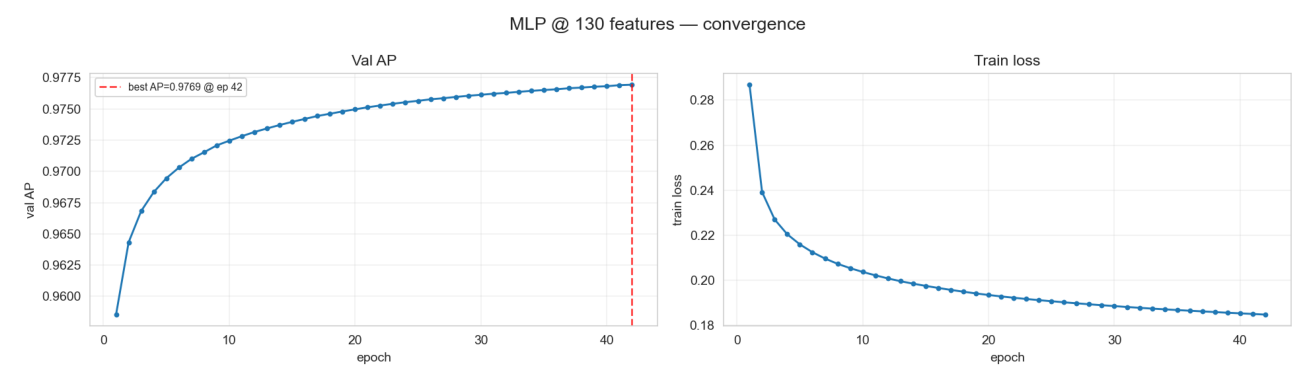

In [ ]:
if "aps" in diag_mlp:
    _fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Left subplot — val AP
    ax = axes[0]
    ap = diag_mlp["aps"]
    best_i = int(np.argmax(ap))
    ax.plot(np.arange(1, len(ap) + 1), ap, marker="o", markersize=3, linewidth=1.5)
    ax.axvline(
        best_i + 1,
        color="r",
        ls="--",
        alpha=0.7,
        label=f"best AP={ap[best_i]:.4f} @ ep {best_i + 1}",
    )
    ax.set_title("Val AP")
    ax.set_xlabel("epoch")
    ax.set_ylabel("val AP")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

    # Right subplot — train loss
    ax = axes[1]
    loss = diag_mlp["losses"]
    ax.plot(np.arange(1, len(loss) + 1), loss, marker="o", markersize=3, linewidth=1.5)
    ax.set_title("Train loss")
    ax.set_xlabel("epoch")
    ax.set_ylabel("train loss")
    ax.grid(alpha=0.3)

    plt.suptitle(f"MLP @ {len(PRETRAINED_FEAT)} features — convergence", fontsize=14)
    plt.tight_layout()
    plt.savefig(PATHS["plots_dir"] / "convergence_mlp.png", dpi=140)
    plt.show()
else:
    conv_img = PATHS["plots_dir"] / "convergence_mlp.png"
    if conv_img.exists():
        print("Convergence plot loaded from disk")
        img = plt.imread(conv_img)
        h, w = img.shape[:2]
        aspect = h / w
        _fig, ax = plt.subplots(figsize=(14, 14 * aspect))
        ax.imshow(img)
        ax.axis("off")
        plt.tight_layout()

In [52]:
print(f"epochs_run={diag_mlp['epochs_run']} stopped={diag_mlp['stopped_reason']}")
print(
    f"ap_at_30={diag_mlp['ap_at_30']:.4f} "
    f"ap_at_plateau={diag_mlp['ap_at_plateau']:.4f} "
    f"gap_pp={diag_mlp['gap_pp']:+.2f}"
)

epochs_run=42 stopped=plateau
ap_at_30=0.9761 ap_at_plateau=0.9769 gap_pp=+0.08


In [53]:
def get_X_scaled(name, X_raw):
    if MODEL_REGISTRY[name]["scale"]:
        arr = scaler.transform(X_raw).astype("float32")
        return pd.DataFrame(arr, columns=X_raw.columns, index=X_raw.index)
    return X_raw


def _benchmark_latency(model, X_one, X_batch):
    for _ in range(LATENCY_WARMUP):
        _ = model.predict_proba(X_one)
    t0 = time.perf_counter()
    for _ in range(LATENCY_REPEATS):
        _ = model.predict_proba(X_one)
    single_ms = (time.perf_counter() - t0) / LATENCY_REPEATS * 1000

    for _ in range(5):
        _ = model.predict_proba(X_batch)
    t0 = time.perf_counter()
    for _ in range(20):
        _ = model.predict_proba(X_batch)
    batch_1024_s = (time.perf_counter() - t0) / 20

    _buf = io.BytesIO()
    joblib.dump(model, _buf)
    size_mb = _buf.tell() / 1e6
    del _buf

    return {
        "single_ms": single_ms,
        "batch_1024_s": batch_1024_s,
        "throughput_domains_s": 1024 / batch_1024_s,
        "size_mb": size_mb,
    }


X_val_raw = full_df.iloc[val_idx][PRETRAINED_FEAT].astype("float32")
X_test_id_raw = full_df.iloc[test_id_idx][PRETRAINED_FEAT].astype("float32")
X_test_ood_raw = full_df.iloc[test_ood_idx][PRETRAINED_FEAT].astype("float32")

baseline_probs = {"val": {}, "test_id": {}, "test_ood": {}}
baseline_metrics = {}

for name, m in trained_models.items():
    probs = {}
    for split, X_raw in [
        ("val", X_val_raw),
        ("test_id", X_test_id_raw),
        ("test_ood", X_test_ood_raw),
    ]:
        p = m.predict_proba(get_X_scaled(name, X_raw))
        p = p[:, 1] if p.ndim == 2 else p
        baseline_probs[split][name] = p
        probs[split] = p

    thr, _, _ = pick_threshold(y_val, probs["val"], TARGET_FPR)
    assert np.isclose(thr, PRETRAINED_THRESHOLDS[name], atol=1e-3), (
        f"{name}: recomputed thr {thr:.4f} != artifact {PRETRAINED_THRESHOLDS[name]:.4f}. "
        "Loaded .pkl differs from artifact."
    )

    m_id = full_metrics_block(y_test_id, probs["test_id"], thr)
    m_od = full_metrics_block(y_test_ood, probs["test_ood"], thr)
    fam = per_family_recall(df_test_ood, probs["test_ood"], thr)
    lat = _benchmark_latency(
        m,
        get_X_scaled(name, X_test_ood_raw.iloc[:1]),
        get_X_scaled(name, X_test_ood_raw.iloc[:1024]),
    )
    lat["n_features"] = len(PRETRAINED_FEAT)

    baseline_metrics[name] = {
        "threshold": thr,
        "train_s": float("nan"),
        "latency": lat,
        "metrics_id": m_id,
        "metrics_ood": m_od,
        "per_family_recall_ood": fam,
    }

print("=== Baseline (from .pkl) ===")
for n in sorted(
    baseline_metrics, key=lambda x: -baseline_metrics[x]["metrics_ood"]["pr_auc"]
):
    m = baseline_metrics[n]["metrics_ood"]
    lat = baseline_metrics[n]["latency"]
    print(
        f"  {n:15s} | ood_ap={m['pr_auc']:.4f} | ood_tpr@0.001={m['tpr@fpr=0.001']:.4f} "
        f"| latency={lat['single_ms']:.2f}ms | size={lat['size_mb']:.2f}MB"
    )

=== Baseline (from .pkl) ===
  MLP             | ood_ap=0.9629 | ood_tpr@0.001=0.5799 | latency=0.74ms | size=0.28MB
  LightGBM        | ood_ap=0.9612 | ood_tpr@0.001=0.5863 | latency=1.35ms | size=10.48MB
  XGBoost         | ood_ap=0.9602 | ood_tpr@0.001=0.5872 | latency=4.35ms | size=10.41MB
  RandomForest    | ood_ap=0.9442 | ood_tpr@0.001=0.5127 | latency=17.96ms | size=68.25MB
  CustomLogReg    | ood_ap=0.9377 | ood_tpr@0.001=0.2969 | latency=0.03ms | size=0.00MB
  SkLogReg        | ood_ap=0.9369 | ood_tpr@0.001=0.2798 | latency=0.76ms | size=0.01MB


In [54]:
known_cols = set(PRETRAINED_FEAT) | {"domain", "label", "class"}
extra_cols = [c for c in full_df.columns if c not in known_cols]

print(f"Total columns in full_df: {len(full_df.columns)}")
print(f"- model features (PRETRAINED_FEAT): {len(PRETRAINED_FEAT)}")
print(f"- labels/meta: {len(known_cols - set(PRETRAINED_FEAT))} (domain, label, class)")
print(f"- extra (unused): {len(extra_cols)}")

if extra_cols:
    print("\nExtra columns (dropped from model input):")
    for c in extra_cols:
        print(f"- {c:30s} | dtype={full_df[c].dtype} | n_unique={full_df[c].nunique()}")
    print("\nSample values (first 3 rows):")
    print(full_df[extra_cols].head(3).to_string())
else:
    print("\nNo extra columns")

Total columns in full_df: 135
- model features (PRETRAINED_FEAT): 130
- labels/meta: 3 (domain, label, class)
- extra (unused): 2

Extra columns (dropped from model input):
- nlp_2g_tske                    | dtype=float64 | n_unique=1980747
- nlp_3g_tske                    | dtype=float64 | n_unique=1645891

Sample values (first 3 rows):
   nlp_2g_tske  nlp_3g_tske
0    20.140800   109.492561
1    24.425470   216.000000
2    24.515375   124.036399


### Section 2. Feature analysis

- Spearman correlation on 50 k train sample → pairs with |ρ| > 0.99 → dedupe list
- Hierarchical clustering (average linkage, 1 − |ρ|) → clusters at ρ > {0.99, 0.95, 0.90}
- Native + permutation feature importances per model → consensus `mean_rank`
- Cumulative importance: how many features cover 90/95 % per model

In [55]:
print("Computing Spearman correlation on train...")
sample_n = 50_000
rng = np.random.RandomState(SEED)
sample_pos = rng.choice(
    len(train_idx), size=min(sample_n, len(train_idx)), replace=False
)
X_sample = full_df.iloc[train_idx[sample_pos]][PRETRAINED_FEAT].astype("float32")

# Spearman на сэмпле + nan-фичи sentinel=-1 уже заполнены, NaN не будет
corr_matrix = X_sample.corr(method="spearman").abs()
print(f"Correlation matrix: {corr_matrix.shape}")

# Пары с rho > 0.99
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = []
for col in upper.columns:
    for row in upper.index:
        val = upper.loc[row, col]
        if pd.notna(val) and val > 0.99:
            high_corr_pairs.append((row, col, float(val)))
high_corr_pairs.sort(key=lambda x: -x[2])
print(f"\nPairs with |rho| > 0.99: {len(high_corr_pairs)}")
for a, b, r in high_corr_pairs[:20]:
    print(f"  {a:25s} ~ {b:25s} | rho={r:.4f}")

Computing Spearman correlation on train...
Correlation matrix: (130, 130)

Pairs with |rho| > 0.99: 214
  nlp_1g_pstd               ~ nlp_1g_pvar               | rho=1.0000
  nlp_1g_pstd               ~ nlp_1g_qmean              | rho=1.0000
  nlp_1g_pvar               ~ nlp_1g_qmean              | rho=1.0000
  nlp_1g_pstd               ~ nlp_1g_std                | rho=1.0000
  nlp_1g_pvar               ~ nlp_1g_std                | rho=1.0000
  nlp_1g_qmean              ~ nlp_1g_std                | rho=1.0000
  nlp_1g_pstd               ~ nlp_1g_var                | rho=1.0000
  nlp_1g_pvar               ~ nlp_1g_var                | rho=1.0000
  nlp_1g_qmean              ~ nlp_1g_var                | rho=1.0000
  nlp_1g_std                ~ nlp_1g_var                | rho=1.0000
  nlp_2g_dst_ji             ~ nlp_2g_dst_ma             | rho=1.0000
  nlp_2g_pstd               ~ nlp_2g_pvar               | rho=1.0000
  nlp_2g_pstd               ~ nlp_2g_qmean              | rho=1.0000

In [56]:
# distance = 1 - |rho|, квадратная форма для linkage
dist_matrix = 1.0 - corr_matrix.fillna(0).values
np.fill_diagonal(dist_matrix, 0)
dist_matrix = np.clip(dist_matrix, 0, 1)

# condensed form
condensed = squareform(dist_matrix, checks=False)
Z = linkage(condensed, method="average")

clusters_at = {}
for thr in [0.99, 0.95, 0.90]:
    labels = fcluster(Z, t=1 - thr, criterion="distance")
    clusters_at[thr] = pd.Series(labels, index=corr_matrix.columns)
    n_clusters = len(np.unique(labels))
    sizes = pd.Series(labels).value_counts()
    print(
        f"rho > {thr}: {n_clusters} clusters | "
        f"largest={sizes.iloc[0]}, median={sizes.median():.0f}"
    )

rho > 0.99: 78 clusters | largest=15, median=1
rho > 0.95: 64 clusters | largest=25, median=1
rho > 0.9: 56 clusters | largest=28, median=1


In [57]:
feature_summary = pd.DataFrame(index=PRETRAINED_FEAT)

# Native importance (5 models; MLP = permutation)
for name in MODEL_REGISTRY:
    m = trained_models[name]
    if name == "LightGBM":
        imp = pd.Series(
            m.booster_.feature_importance(importance_type="gain"), index=PRETRAINED_FEAT
        )
    elif name in ("XGBoost", "RandomForest"):
        imp = pd.Series(m.feature_importances_, index=PRETRAINED_FEAT)
    elif name in ("CustomLogReg", "SkLogReg"):
        coef = m.coef_[0] if name == "SkLogReg" else m.weights[1:]
        imp = pd.Series(np.abs(coef), index=PRETRAINED_FEAT)
    else:  # MLP — permutation on VAL
        X_perm = get_X_scaled(name, X_val_raw)
        perm_idx = rng.choice(len(X_perm), size=10_000, replace=False)
        pi = permutation_importance(
            m,
            X_perm.iloc[perm_idx],
            y_val[perm_idx],
            scoring="average_precision",
            n_repeats=3,
            random_state=SEED,
            n_jobs=1,
        )
        imp = pd.Series(pi.importances_mean, index=PRETRAINED_FEAT)

        # Сheck
        if imp.abs().sum() < 1e-6:
            print(
                f"{name}: permutation returned all zeros."
                f"shape={pi.importances.shape}, sample={pi.importances[:3]}"
            )
            raise RuntimeError(f"permutation_importance failed for {name}")
    feature_summary[f"imp_{name}"] = imp.values
    feature_summary[f"rank_{name}"] = imp.rank(ascending=False).values

# Consensus
rank_cols = [c for c in feature_summary.columns if c.startswith("rank_")]
feature_summary["mean_rank"] = feature_summary[rank_cols].mean(axis=1)
feature_summary["n_top_20"] = (feature_summary[rank_cols] <= 20).sum(axis=1)
feature_summary["n_top_50"] = (feature_summary[rank_cols] <= 50).sum(axis=1)

feature_summary = feature_summary.sort_values("mean_rank")
print("=== Top-20 by consensus ===")
print(feature_summary[["mean_rank", "n_top_20"]].head(20).round(1).to_string())

=== Top-20 by consensus ===
                mean_rank  n_top_20
nlp_r_sym_fqdn        7.3         6
nlp_lc_c             10.0         4
nlp_l_2dn            13.7         5
nlp_2g_e             17.0         4
nlp_3g_norm          17.3         4
nlp_1g_dst_em        18.5         4
nlp_l_odn            20.8         3
nlp_r_sym_2dn        21.3         3
nlp_3g_e             22.5         4
nlp_3g_tpstd         23.3         4
nlp_2g_dst_em        25.0         4
nlp_r_let_fqdn       26.7         4
nlp_3g_pro           27.8         3
nlp_2g_dist          28.3         3
nlp_r_con_2dn        29.0         3
nlp_2g_pea           31.5         2
nlp_r_num_fqdn       31.5         3
nlp_2g_norm          32.0         3
nlp_lc_n             32.2         2
nlp_1g_e             33.5         2


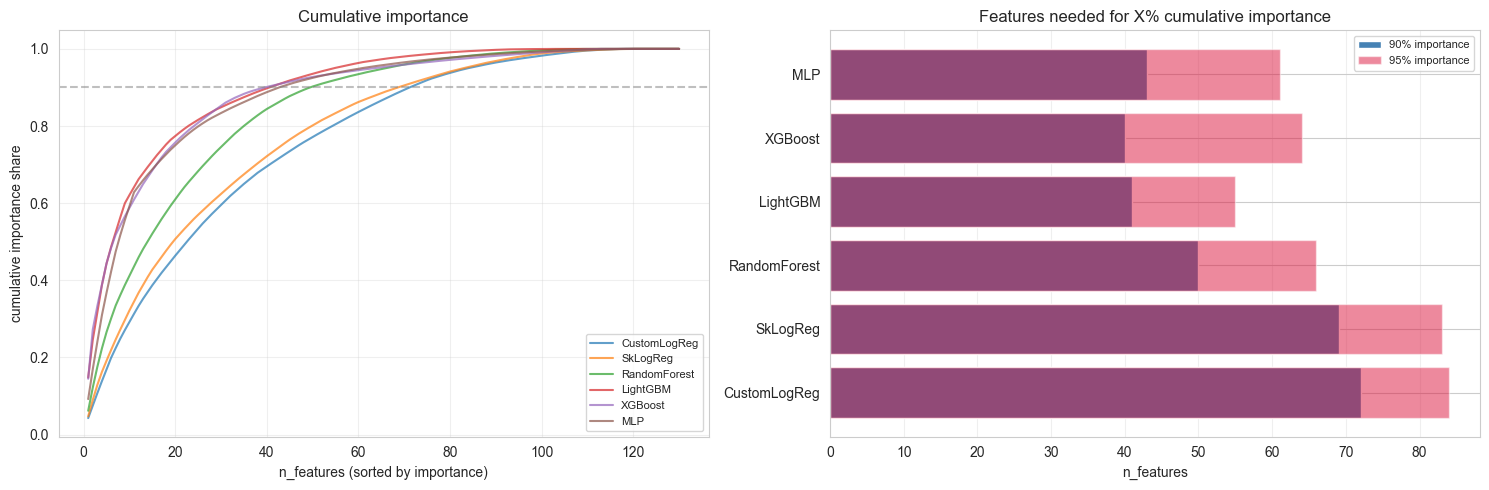

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: AP vs n_features — only "importance >= threshold"
ax = axes[0]
for name in MODEL_REGISTRY:
    imp_col = f"imp_{name}"
    if imp_col not in feature_summary:
        continue
    vals = feature_summary[imp_col].values
    order = np.argsort(-vals)
    cumsum = np.cumsum(vals[order]) / (vals.sum() + 1e-9)
    ax.plot(np.arange(1, len(cumsum) + 1), cumsum, label=name, alpha=0.7, linewidth=1.5)
ax.set_xlabel("n_features (sorted by importance)")
ax.set_ylabel("cumulative importance share")
ax.set_title("Cumulative importance")
ax.axhline(0.9, color="gray", ls="--", alpha=0.5)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Right: count features for 90% importance for each model
ax = axes[1]
thresholds_needed = {}
for name in MODEL_REGISTRY:
    imp_col = f"imp_{name}"
    if imp_col not in feature_summary:
        continue
    vals = feature_summary[imp_col].values
    order = np.argsort(-vals)
    cumsum = np.cumsum(vals[order]) / (vals.sum() + 1e-9)
    n_for_90 = int(np.searchsorted(cumsum, 0.9) + 1)
    n_for_95 = int(np.searchsorted(cumsum, 0.95) + 1)
    thresholds_needed[name] = {"n_for_90pct": n_for_90, "n_for_95pct": n_for_95}

ax.barh(
    list(thresholds_needed),
    [v["n_for_90pct"] for v in thresholds_needed.values()],
    color="steelblue",
    label="90% importance",
)
ax.barh(
    list(thresholds_needed),
    [v["n_for_95pct"] for v in thresholds_needed.values()],
    color="crimson",
    alpha=0.5,
    label="95% importance",
)
ax.set_xlabel("n_features")
ax.set_title("Features needed for X% cumulative importance")
ax.legend(fontsize=8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "cumulative_importance.png", dpi=140)
plt.show()

In [59]:
print("=== Features needed for 90%/95% importance ===")
for n, v in thresholds_needed.items():
    print(f"  {n:15s} | 90%: {v['n_for_90pct']:3d} | 95%: {v['n_for_95pct']:3d}")

=== Features needed for 90%/95% importance ===
  CustomLogReg    | 90%:  72 | 95%:  84
  SkLogReg        | 90%:  69 | 95%:  83
  RandomForest    | 90%:  50 | 95%:  66
  LightGBM        | 90%:  41 | 95%:  55
  XGBoost         | 90%:  40 | 95%:  64
  MLP             | 90%:  43 | 95%:  61


In [60]:
imp_mlp = feature_summary["imp_MLP"].values
print(f"imp_MLP.sum()   = {imp_mlp.sum():+.6f}       ← ключевое")
print(f"imp_MLP.min/max = {imp_mlp.min():+.6f} / {imp_mlp.max():+.6f}")
print(f"#positive / #negative = {(imp_mlp > 0).sum()} / {(imp_mlp < 0).sum()}")
print(f"#exactly-zero         = {(imp_mlp == 0).sum()}")

# Cumsum check
vals = imp_mlp
order = np.argsort(-vals)
cumsum = np.cumsum(vals[order]) / (vals.sum() + 1e-9)
print(f"\ncumsum is monotonic: {bool(np.all(np.diff(cumsum) >= 0))}")
print(f"cumsum[-1] = {cumsum[-1]:.4f}")
print(f"first index where cumsum >= 0.9: {np.searchsorted(cumsum, 0.9)}")

imp_MLP.sum()   = +2.166037       ← ключевое
imp_MLP.min/max = +0.000000 / +0.199036
#positive / #negative = 120 / 0
#exactly-zero         = 10

cumsum is monotonic: True
cumsum[-1] = 1.0000
first index where cumsum >= 0.9: 42


### Section 3. Feature reduction stages

Evaluated on all 6 models at every stage (to detect model-specific sensitivity).

| Stage | Features | What |
|---|---|---|
| S0 | 130 | baseline (`.pkl`) |
| S1 | 77 | drop one from each ρ > 0.99 pair (keep higher mean_rank) |
| S2 | 53 | top-70 % of S1 by mean_rank |
| S3 | 42–53 | S2 minus one semantic group (`isnan` / `ratio` / `len` / `3g`) |

S3 ablations are independent (each removes one group from S2), not cumulative.
`S3_no_isnan` converges to `S2_clean` (isnan features are already low-rank) — kept for illustration.

In [61]:
def fit_mlp_with_early_stop(
    model,
    X_tr,
    y_tr,
    X_va,
    y_va,
    max_epochs=60,
    patience=5,
    min_delta=1e-4,
    verbose=True,
):
    """
    warm_start MLP with external early stopping on val AP.
    - Uses the caller's X_va (not internal validation_fraction).
    - Restores best_state (by val AP) via deepcopy — safe copy of _optimizer + weights.
    """
    best_ap, best_state, patience_counter = -np.inf, None, 0
    history = {"epoch": [], "val_ap": []}

    for epoch in range(max_epochs):
        model.fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]
        ap = average_precision_score(y_va, p)
        history["epoch"].append(epoch + 1)
        history["val_ap"].append(float(ap))

        if verbose and (epoch < 5 or (epoch + 1) % 5 == 0):
            print(f"  epoch {epoch + 1:2d} | val_ap {ap:.4f} | best {best_ap:.4f}")

        if ap > best_ap + min_delta:
            best_ap = ap
            best_state = deepcopy(model)
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                if verbose:
                    print(f"  early stop at epoch {epoch + 1} (patience={patience})")
                break

    if best_state is not None:
        model = best_state
    return model, history

def fit_model(model, name, X_tr, y_tr, X_va, y_va, seed=SEED):
    Xtr_v = X_tr.values if hasattr(X_tr, "values") else X_tr
    Xva_v = X_va.values if hasattr(X_va, "values") else X_va
    rng = np.random.RandomState(seed)

    if name == "CustomLogReg":
        model.fit(Xtr_v, y_tr, eval_set=[(Xva_v, y_va)])
    elif name == "SkLogReg":
        for _ in range(50):
            idx = rng.permutation(len(X_tr))
            model.partial_fit(X_tr.iloc[idx], y_tr[idx], classes=[0, 1])
    elif name == "RandomForest":
        for _ in range(10):
            model.set_params(n_estimators=model.n_estimators + 10)
            model.fit(X_tr, y_tr)
    elif name == "LightGBM":
        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_va, y_va)],
            eval_metric="average_precision",
            callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(0)],
        )
    elif name == "XGBoost":
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    elif name == "MLP":
        model, _ = fit_mlp_with_early_stop(
            model,
            X_tr.values,
            y_tr,
            X_va.values,
            y_va,
            max_epochs=45,
            patience=5,
            min_delta=1e-4,
            verbose=False,
        )
    return model


def predict_proba_1d(model, X):
    p = model.predict_proba(X)
    return p[:, 1] if p.ndim == 2 else p


def evaluate_feature_set(feature_list, label, models=None, seed=SEED, cache_kind="stages"):
    if models is None:
        models = list(MODEL_REGISTRY)

    X_tr_raw = full_df.iloc[train_idx][feature_list].astype("float32")
    X_va_raw = full_df.iloc[val_idx][feature_list].astype("float32")
    X_id_raw = full_df.iloc[test_id_idx][feature_list].astype("float32")
    X_od_raw = full_df.iloc[test_ood_idx][feature_list].astype("float32")

    cache_dir = STAGE_CACHE if cache_kind == "stages" else KSWEEP_CACHE

    results = {"label": label, "n_features": len(feature_list), "models": {}}
    print(f"\n{'=' * 60}\n{label} | n_features={len(feature_list)}\n{'=' * 60}")

    for name in models:
        cache_file = cache_dir / f"{label}__{name}.pkl"
        if TRAIN_CACHE and not CACHE_RESET and cache_file.exists():
            results["models"][name] = joblib.load(cache_file)
            m = results["models"][name]
            print(f"  {name:15s} | cached | id_ap={m['metrics_id']['pr_auc']:.4f} "
                  f"| ood_ap={m['metrics_ood']['pr_auc']:.4f} "
                  f"| ood_tpr@0.001={m['metrics_ood']['tpr@fpr=0.001']:.4f}")
            continue
        cfg = MODEL_REGISTRY[name]
        if cfg["scale"]:
            sc = StandardScaler().fit(X_tr_raw)
            Xtr = pd.DataFrame(sc.transform(X_tr_raw), columns=feature_list)
            Xva = pd.DataFrame(sc.transform(X_va_raw), columns=feature_list)
            Xid = pd.DataFrame(sc.transform(X_id_raw), columns=feature_list)
            Xod = pd.DataFrame(sc.transform(X_od_raw), columns=feature_list)
        else:
            Xtr, Xva, Xid, Xod = X_tr_raw, X_va_raw, X_id_raw, X_od_raw

        model = cfg["builder"]()
        t0 = time.perf_counter()
        model = fit_model(model, name, Xtr, y_all[train_idx], Xva, y_val, seed=seed)
        train_s = time.perf_counter() - t0

        p_val = predict_proba_1d(model, Xva)
        p_id = predict_proba_1d(model, Xid)
        p_od = predict_proba_1d(model, Xod)

        thr, _, _ = pick_threshold(y_val, p_val, TARGET_FPR)
        m_id = full_metrics_block(y_test_id, p_id, thr)
        m_od = full_metrics_block(y_test_ood, p_od, thr)
        fam = per_family_recall(df_test_ood, p_od, thr)
        lat = _benchmark_latency(model, Xod.iloc[:1], Xod.iloc[:1024])
        lat["n_features"] = len(feature_list)

        results["models"][name] = {
            "model": model,
            "threshold": thr,
            "train_s": train_s,
            "metrics_id": m_id,
            "metrics_ood": m_od,
            "per_family_recall_ood": fam,
            "probs": {"val": p_val, "test_id": p_id, "test_ood": p_od},
            "latency": lat,
        }
        print(
            f"  {name:15s} | id_ap={m_id['pr_auc']:.4f} | ood_ap={m_od['pr_auc']:.4f} "
            f"| ood_tpr@0.001={m_od['tpr@fpr=0.001']:.4f} | {train_s:.0f}s "
            f"| {lat['single_ms']:.2f}ms | {lat['size_mb']:.2f}MB"
        )
        if TRAIN_CACHE:
            entry = {k: v for k, v in results["models"][name].items() if k != "probs"}
            if cache_kind == "stages":
                entry.pop("model", None)
            joblib.dump(entry, cache_file)
        gc.collect()
    return results


def build_feats_reduced(feature_list, summary_df, top_pct=0.30):
    """Top (1 - top_pct) features by mean_rank, no cluster protection."""
    n_keep = int(len(feature_list) * (1 - top_pct))
    ranked = summary_df.loc[feature_list].sort_values("mean_rank").index.tolist()
    return ranked[:n_keep]

In [62]:
stage_results = {}

stage_results["S0_baseline"] = {
    "label": "S0_baseline",
    "n_features": len(PRETRAINED_FEAT),
    "models": {
        n: {
            "metrics_id": baseline_metrics[n]["metrics_id"],
            "metrics_ood": baseline_metrics[n]["metrics_ood"],
            "per_family_recall_ood": baseline_metrics[n]["per_family_recall_ood"],
            "threshold": baseline_metrics[n]["threshold"],
            "train_s": baseline_metrics[n]["train_s"],
            "latency": baseline_metrics[n]["latency"],
            "probs": {s: baseline_probs[s][n] for s in ("val", "test_id", "test_ood")},
        }
        for n in MODEL_REGISTRY
    },
}

drop_dupes = set()
for a, b, _ in high_corr_pairs:
    ra = feature_summary.loc[a, "mean_rank"]
    rb = feature_summary.loc[b, "mean_rank"]
    drop_dupes.add(b if ra < rb else a)
feats_s1 = [c for c in PRETRAINED_FEAT if c not in drop_dupes]
stage_results["S1_no_dupes"] = evaluate_feature_set(feats_s1, "S1_no_dupes")

feats_s2 = build_feats_reduced(feats_s1, feature_summary, top_pct=0.30)
stage_results["S2_top70pct"] = evaluate_feature_set(feats_s2, "S2_top70pct")

FEATURE_GROUPS = {
    "1g": [c for c in PRETRAINED_FEAT if c.startswith("nlp_1g_")],
    "2g": [c for c in PRETRAINED_FEAT if c.startswith("nlp_2g_")],
    "3g": [c for c in PRETRAINED_FEAT if c.startswith("nlp_3g_")],
    "len": [c for c in PRETRAINED_FEAT if c.startswith(("nlp_l_", "nlp_lc_", "nlp_n"))],
    "ratio": [c for c in PRETRAINED_FEAT if c.startswith("nlp_r_")],
    "isnan": [c for c in PRETRAINED_FEAT if c.startswith("isnan_")],
}
for grp in ["isnan", "ratio", "len", "3g"]:
    feats = [c for c in feats_s2 if c not in FEATURE_GROUPS[grp]]
    stage_results[f"S3_no_{grp}"] = evaluate_feature_set(feats, f"S3_no_{grp}")


S1_no_dupes | n_features=77
  CustomLogReg    | id_ap=0.9149 | ood_ap=0.9346 | ood_tpr@0.001=0.2796 | 58s | 0.03ms | 0.00MB
  SkLogReg        | id_ap=0.9153 | ood_ap=0.9308 | ood_tpr@0.001=0.2224 | 60s | 0.63ms | 0.00MB
  RandomForest    | id_ap=0.9621 | ood_ap=0.9458 | ood_tpr@0.001=0.5200 | 118s | 17.67ms | 69.77MB
  LightGBM        | id_ap=0.9810 | ood_ap=0.9587 | ood_tpr@0.001=0.5637 | 244s | 1.52ms | 17.79MB
  XGBoost         | id_ap=0.9809 | ood_ap=0.9583 | ood_tpr@0.001=0.5744 | 342s | 4.03ms | 12.81MB
  MLP             | id_ap=0.9761 | ood_ap=0.9651 | ood_tpr@0.001=0.5692 | 161s | 0.63ms | 0.17MB

S2_top70pct | n_features=53
  CustomLogReg    | id_ap=0.9141 | ood_ap=0.9340 | ood_tpr@0.001=0.2961 | 40s | 0.03ms | 0.00MB
  SkLogReg        | id_ap=0.9145 | ood_ap=0.9303 | ood_tpr@0.001=0.2484 | 45s | 0.59ms | 0.00MB
  RandomForest    | id_ap=0.9634 | ood_ap=0.9478 | ood_tpr@0.001=0.5213 | 117s | 27.99ms | 69.11MB
  LightGBM        | id_ap=0.9809 | ood_ap=0.9589 | ood_tpr@0.001=0.

In [63]:
def build_stage_table(stage_results, metric="pr_auc"):
    rows = []
    for label, r in stage_results.items():
        for name, m in r["models"].items():
            n_feat = (
                int(r["n_features"])
                if isinstance(r["n_features"], Integral)
                else int(r["n_features"].get(name, len(PRETRAINED_FEAT)))
            )
            lat = m.get("latency") or {}
            rows.append(
                {
                    "stage": label,
                    "model": name,
                    "n_features": n_feat,
                    "id_ap": m["metrics_id"][metric],
                    "ood_ap": m["metrics_ood"][metric],
                    "ood_tpr@1e-3": m["metrics_ood"]["tpr@fpr=0.001"],
                    "ood_fpr": m["metrics_ood"]["fpr"],
                    "ood_brier": m["metrics_ood"]["brier"],
                    "train_s": m["train_s"],
                    "single_ms": lat.get("single_ms", float("nan")),
                    "size_mb": lat.get("size_mb", float("nan")),
                }
            )
    return pd.DataFrame(rows)


stage_table = build_stage_table(stage_results)

print("=== OOD AP by model × stage ===")
pivot_ood = stage_table.pivot_table(index="model", columns="stage", values="ood_ap")
print(pivot_ood.round(4).to_string())

print("\n=== OOD TPR@FPR=1e-3 by model × stage ===")
pivot_tpr = stage_table.pivot_table(
    index="model", columns="stage", values="ood_tpr@1e-3"
)
print(pivot_tpr.round(4).to_string())

baseline_ood = {n: baseline_metrics[n]["metrics_ood"]["pr_auc"] for n in MODEL_REGISTRY}
baseline_tpr = {
    n: baseline_metrics[n]["metrics_ood"]["tpr@fpr=0.001"] for n in MODEL_REGISTRY
}

delta_table = stage_table.copy()
delta_table["delta_ood_ap_pp"] = delta_table.apply(
    lambda r: (r["ood_ap"] - baseline_ood[r["model"]]) * 100, axis=1
)
delta_table["delta_ood_tpr_pp"] = delta_table.apply(
    lambda r: (r["ood_tpr@1e-3"] - baseline_tpr[r["model"]]) * 100, axis=1
)

pivot_delta_ap = delta_table.pivot_table(
    index="model", columns="stage", values="delta_ood_ap_pp"
)
pivot_delta_tpr = delta_table.pivot_table(
    index="model", columns="stage", values="delta_ood_tpr_pp"
)

print("\n=== Δ OOD AP vs baseline (pp) ===")
print(pivot_delta_ap.round(2).to_string())
print("\n=== Δ OOD TPR@FPR=1e-3 vs baseline (pp) ===")
print(pivot_delta_tpr.round(2).to_string())

=== OOD AP by model × stage ===
stage         S0_baseline  S1_no_dupes  S2_top70pct  S3_no_3g  S3_no_isnan  S3_no_len  S3_no_ratio
model                                                                                             
CustomLogReg       0.9377       0.9346       0.9340    0.9263       0.9340     0.9279       0.9276
LightGBM           0.9612       0.9587       0.9589    0.9519       0.9587     0.9567       0.9644
MLP                0.9629       0.9651       0.9664    0.9624       0.9664     0.9645       0.9649
RandomForest       0.9442       0.9458       0.9478    0.9434       0.9478     0.9449       0.9497
SkLogReg           0.9369       0.9308       0.9303    0.9207       0.9303     0.9239       0.9245
XGBoost            0.9602       0.9583       0.9573    0.9518       0.9573     0.9561       0.9645

=== OOD TPR@FPR=1e-3 by model × stage ===
stage         S0_baseline  S1_no_dupes  S2_top70pct  S3_no_3g  S3_no_isnan  S3_no_len  S3_no_ratio
model                             

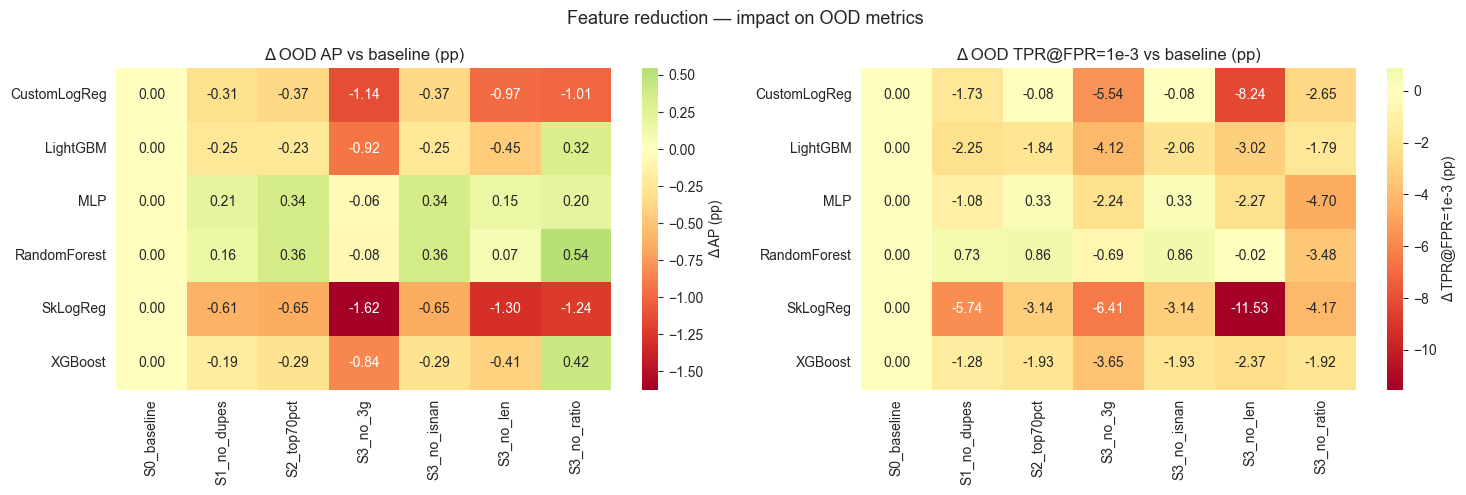

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(
    pivot_delta_ap,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    ax=axes[0],
    cbar_kws={"label": "Δ AP (pp)"},
)
axes[0].set_title("Δ OOD AP vs baseline (pp)")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

sns.heatmap(
    pivot_delta_tpr,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    ax=axes[1],
    cbar_kws={"label": "Δ TPR@FPR=1e-3 (pp)"},
)
axes[1].set_title("Δ OOD TPR@FPR=1e-3 vs baseline (pp)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.suptitle("Feature reduction — impact on OOD metrics", fontsize=13)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "reduction_heatmap.png", dpi=140)
plt.show()

### Section 4. Sensitivity and group ablation

- Per-model sensitivity: `mean_abs_delta_ap_pp` / `mean_abs_delta_tpr_pp` across all reduction stages
- Group ablation heatmap: Δ OOD AP and Δ OOD TPR@fpr=1e-3 per (model, removed group) relative to S2
- `len` and `ratio` are the load-bearing groups for every model; `isnan` is free

In [65]:
rank_cols = [c for c in feature_summary.columns if c.startswith("rank_")]
top30_mask = feature_summary[rank_cols] <= 30
feature_summary["n_top_30"] = top30_mask.sum(axis=1)
feature_summary["n_top_10"] = (feature_summary[rank_cols] <= 10).sum(axis=1)

core_set = feature_summary[feature_summary["n_top_30"] >= 5].index.tolist()
consensus_5_of_6 = feature_summary[feature_summary["n_top_30"] >= 5].shape[0]
consensus_6_of_6 = feature_summary[feature_summary["n_top_30"] == 6].shape[0]
print(f"Features in top-30 for 5/6 models: {consensus_5_of_6}")
print(f"Features in top-30 for 6/6 models: {consensus_6_of_6}")
print(f"\nCore set (5+ of 6): {core_set}")

# Model-specific features (top-10, deduped, outside core set)
CORE_SET = set(core_set)
UNIQUE_FEATURES = {c for c in PRETRAINED_FEAT if c not in drop_dupes}

model_specific = {}
for name in MODEL_REGISTRY:
    top10 = feature_summary[feature_summary[f"rank_{name}"] <= 10].index.tolist()
    # Exclude duplicates (keep only one representative per rho>0.99 cluster)
    top10_unique = [c for c in top10 if c in UNIQUE_FEATURES]
    # Exclude core set — we want what's *specific* to this model
    model_specific[name] = [c for c in top10_unique if c not in CORE_SET]

print("\n=== Model-specific features (top-10, deduped, excluding core set) ===")
for n, feats in model_specific.items():
    marker = "- (core set only)" if not feats else ""
    print(f" {n:15s} | {feats}{marker}")

Features in top-30 for 5/6 models: 6
Features in top-30 for 6/6 models: 2

Core set (5+ of 6): ['nlp_r_sym_fqdn', 'nlp_lc_c', 'nlp_l_2dn', 'nlp_2g_e', 'nlp_3g_e', 'nlp_2g_pea']

=== Model-specific features (top-10, deduped, excluding core set) ===
 CustomLogReg    | ['nlp_1g_dst_em', 'nlp_l_odn', 'nlp_3g_tpstd', 'nlp_2g_dst_em', 'nlp_1g_tsum']
 SkLogReg        | ['nlp_1g_dst_em', 'nlp_l_odn', 'nlp_r_sym_2dn', 'nlp_2g_dst_em', 'nlp_r_num_fqdn', 'nlp_1g_e']
 RandomForest    | ['nlp_3g_norm', 'nlp_r_let_fqdn', 'nlp_2g_norm']
 LightGBM        | ['nlp_3g_norm', 'nlp_r_let_fqdn', 'nlp_2g_norm']
 XGBoost         | ['nlp_r_let_fqdn', 'nlp_2g_dist', 'nlp_r_vow_odn']
 MLP             | ['nlp_1g_dst_em', 'nlp_l_odn', 'nlp_3g_tpstd', 'nlp_2g_dst_em', 'nlp_r_num_fqdn']


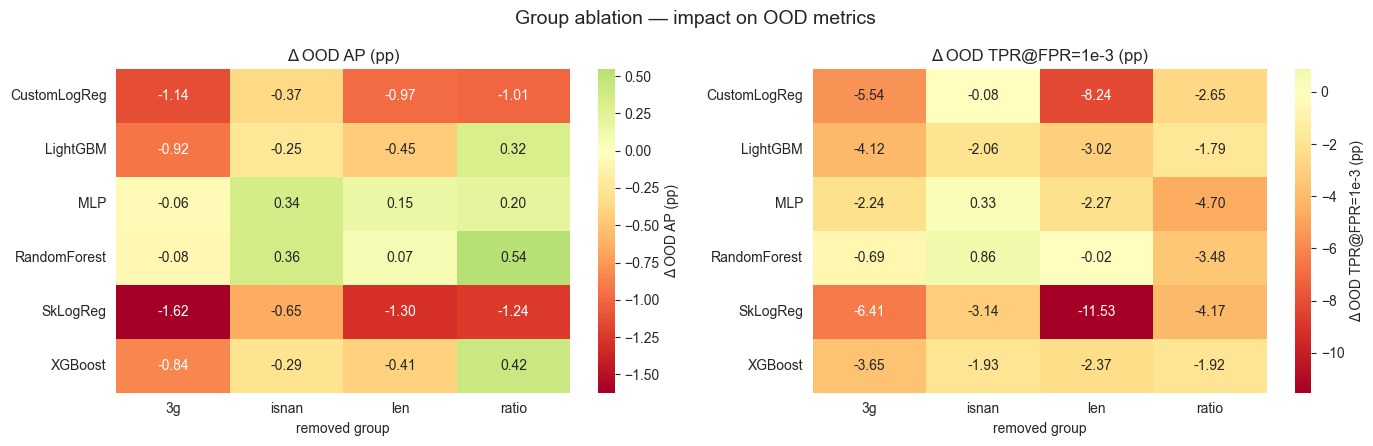

In [66]:
group_delta = delta_table[delta_table["stage"].str.startswith("S3_no_")].copy()
group_delta["group"] = group_delta["stage"].str.replace("S3_no_", "", regex=False)

pivot_group_ap = group_delta.pivot_table(
    index="model", columns="group", values="delta_ood_ap_pp"
)
pivot_group_tpr = group_delta.pivot_table(
    index="model", columns="group", values="delta_ood_tpr_pp"
)

_fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (title, pivot) in zip(
    axes,
    [
        ("Δ OOD AP (pp)", pivot_group_ap),
        ("Δ OOD TPR@FPR=1e-3 (pp)", pivot_group_tpr),
    ],
):
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        cmap="RdYlGn",
        center=0,
        cbar_kws={"label": title},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("removed group")
    ax.set_ylabel("")

plt.suptitle("Group ablation — impact on OOD metrics", fontsize=14)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "group_ablation.png", dpi=140)
plt.show()

In [67]:
sens = (
    delta_table.query("stage != 'S0_baseline'")
    .groupby("model")
    .agg(
        mean_abs_delta_ap_pp=("delta_ood_ap_pp", lambda s: s.abs().mean()),
        mean_abs_delta_tpr_pp=("delta_ood_tpr_pp", lambda s: s.abs().mean()),
        worst_ap_pp=("delta_ood_ap_pp", "min"),
        best_ap_pp=("delta_ood_ap_pp", "max"),
    )
    .astype(float)
)
assert sens.index.is_unique
print("=== Model sensitivity to feature reduction ===")
print(sens.round(2).to_string())

=== Model sensitivity to feature reduction ===
              mean_abs_delta_ap_pp  mean_abs_delta_tpr_pp  worst_ap_pp  best_ap_pp
model                                                                             
CustomLogReg                  0.69                   3.05        -1.14       -0.31
LightGBM                      0.40                   2.51        -0.92        0.32
MLP                           0.22                   1.82        -0.06        0.34
RandomForest                  0.26                   1.11        -0.08        0.54
SkLogReg                      1.01                   5.69        -1.62       -0.61
XGBoost                       0.41                   2.18        -0.84        0.42


### Section 5. Model selection, K-sweep, CV

**Selection rule** (pre-registered in config): best-in-family model with gap ≤ 2 pp to best baseline OOD TPR@fpr=1e-3. Deployment cost (latency/size) is reported, but not used in selection.

**K-sweep** on 4 bases × 5 K values per selected model:
- bases: `S1_no_dupes` (77), `S2_clean` (53), `S3_no_isnan` (53), `S3_no_ratio` (42)
- multi-base avoids starting from an already-damaged set (`S3_no_ratio` had `ratio` removed before K-selection in the previous run)

**K selection protocol** (avoids test-selection bias):
- `tpr_oracle` — argmax on **test_ood** TPR (upper bound, not deployable)
- `tpr_val` — argmax on **val** TPR (**primary**, deployment-realistic)
- `ap` — argmax on test AP (reference)

**CV**: 5-fold GroupKFold on the same folds as `models.ipynb`. Wilcoxon signed-rank (n=5 → min achievable p = 0.0625; direction across folds matters more than p-value).

In [68]:
MODEL_FAMILY = {
    "CustomLogReg": "linear",
    "SkLogReg": "linear",
    "RandomForest": "tree",
    "LightGBM": "tree",
    "XGBoost": "tree",
    "MLP": "neural",
}

selection_df = pd.DataFrame(
    {
        "ood_tpr@1e-3": {
            n: baseline_metrics[n]["metrics_ood"]["tpr@fpr=0.001"]
            for n in MODEL_REGISTRY
        },
        "ood_pr_auc": {
            n: baseline_metrics[n]["metrics_ood"]["pr_auc"] for n in MODEL_REGISTRY
        },
        "ood_brier": {
            n: baseline_metrics[n]["metrics_ood"]["brier"] for n in MODEL_REGISTRY
        },
        "single_ms": {
            n: baseline_metrics[n]["latency"]["single_ms"] for n in MODEL_REGISTRY
        },
        "size_mb": {
            n: baseline_metrics[n]["latency"]["size_mb"] for n in MODEL_REGISTRY
        },
        "family": {n: MODEL_FAMILY[n] for n in MODEL_REGISTRY},
    }
).sort_values("ood_tpr@1e-3", ascending=False)

print("=== Baseline ranking (primary = ood_tpr@fpr=1e-3) ===")
print(selection_df.round(4).to_string())

best_tpr = selection_df["ood_tpr@1e-3"].max()
print(f"\nRule: best-in-family with gap to best TPR ≤ {SELECTION_TOLERANCE_PP}pp")

selected_models = []
for family in ["tree", "neural", "linear"]:
    fam = selection_df[selection_df["family"] == family]
    if len(fam) == 0:
        continue
    rep = fam.index[0]
    gap_pp = (best_tpr - fam.loc[rep, "ood_tpr@1e-3"]) * 100
    ok = gap_pp <= SELECTION_TOLERANCE_PP
    print(
        f"  {family:8s} | {rep:15s} | gap={gap_pp:+6.2f}pp | "
        f"{'SELECTED' if ok else 'excluded'}"
    )
    if ok:
        selected_models.append(rep)

assert len(selected_models) >= 2, f"Selection picked <2 models: {selected_models}"
print(f"\nSelected: {selected_models}")

=== Baseline ranking (primary = ood_tpr@fpr=1e-3) ===
              ood_tpr@1e-3  ood_pr_auc  ood_brier  single_ms  size_mb  family
XGBoost             0.5872      0.9602     0.0923     4.3488  10.4108    tree
LightGBM            0.5863      0.9612     0.0911     1.3496  10.4829    tree
MLP                 0.5799      0.9629     0.0871     0.7399   0.2791  neural
RandomForest        0.5127      0.9442     0.1116    17.9587  68.2545    tree
CustomLogReg        0.2969      0.9377     0.1145     0.0317   0.0043  linear
SkLogReg            0.2798      0.9369     0.1154     0.7594   0.0051  linear

Rule: best-in-family with gap to best TPR ≤ 2.0pp
  tree     | XGBoost         | gap= +0.00pp | SELECTED
  neural   | MLP             | gap= +0.72pp | SELECTED
  linear   | CustomLogReg    | gap=+29.02pp | excluded

Selected: ['XGBoost', 'MLP']


In [69]:
K_SWEEP_BASES = {
    "S1_no_dupes": feats_s1,
    "S2_clean": feats_s2,
    "S3_no_isnan": [c for c in feats_s2 if c not in FEATURE_GROUPS["isnan"]],
    "S3_no_ratio": [c for c in feats_s2 if c not in FEATURE_GROUPS["ratio"]],
}
K_SWEEP_POINTS = [30, 40, 50, 60]

print(f"K-sweep bases: { {k: len(v) for k, v in K_SWEEP_BASES.items()} }")

ksweep_results = {name: {} for name in selected_models}

for name in selected_models:
    for base_label, base_feats in K_SWEEP_BASES.items():
        imp_sorted = feature_summary.loc[base_feats, f"imp_{name}"].sort_values(
            ascending=False
        )
        K_local = sorted(
            {min(k, len(base_feats)) for k in K_SWEEP_POINTS + [len(base_feats)]}
        )

        for k in K_local:
            selected = imp_sorted.head(k).index.tolist()
            res = evaluate_feature_set(
                selected,
                f"S5_{name}_{base_label}_K{k}",
                models=[name],
                cache_kind="ksweep"
            )
            m = res["models"][name]
            ksweep_results[name][(base_label, k)] = {
                "features": selected,
                "base": base_label,
                "n_features": k,
                "id_ap": m["metrics_id"]["pr_auc"],
                "ood_ap": m["metrics_ood"]["pr_auc"],
                "ood_tpr@1e-3": m["metrics_ood"]["tpr@fpr=0.001"],
                "val_tpr@1e-3": tpr_at_fpr(y_val, m["probs"]["val"], TARGET_FPR),
                "ood_fpr": m["metrics_ood"]["fpr"],
                "ood_brier": m["metrics_ood"]["brier"],
                "threshold": m["threshold"],
                "train_s": m["train_s"],
                "latency": m["latency"],
                "probs": m["probs"],
                "per_family_recall_ood": m["per_family_recall_ood"],
                "model": m["model"],
            }

ksweep_df = pd.DataFrame(
    [
        {
            "model": n,
            "base": base,
            "n_features": k,
            "id_ap": r["id_ap"],
            "ood_ap": r["ood_ap"],
            "ood_tpr@1e-3": r["ood_tpr@1e-3"],
            "val_tpr@1e-3": r["val_tpr@1e-3"],
            "ood_fpr": r["ood_fpr"],
            "ood_brier": r["ood_brier"],
            "train_s": r["train_s"],
            "single_ms": r["latency"]["single_ms"],
            "size_mb": r["latency"]["size_mb"],
        }
        for n in selected_models
        for (base, k), r in ksweep_results[n].items()
    ]
).set_index(["model", "base", "n_features"])

print("\n=== K-sweep summary (all bases × K) ===")
print(ksweep_df.round(4).to_string())

best_k = {}
for name in selected_models:
    sub = ksweep_df.loc[name]

    def _best(col, ascending=False, sub=sub):
        idx = sub[col].idxmax() if not ascending else sub[col].idxmin()
        return sub.loc[idx]

    row_tpr_oracle = _best("ood_tpr@1e-3")
    row_tpr_val = _best("val_tpr@1e-3")
    row_ap = _best("ood_ap")

    best_k[name] = {
        "tpr_oracle": {
            "base": row_tpr_oracle.name[0],
            "k": int(row_tpr_oracle.name[1]),
        },
        "tpr_val": {"base": row_tpr_val.name[0], "k": int(row_tpr_val.name[1])},
        "ap": {"base": row_ap.name[0], "k": int(row_ap.name[1])},
    }

    print(f"\n{name}:")
    for key, label in [
        ("tpr_oracle", "oracle test-TPR"),
        ("tpr_val", "honest val-TPR"),
        ("ap", "test AP"),
    ]:
        e = best_k[name][key]
        row = sub.loc[(e["base"], e["k"])]
        print(
            f"  {label:18s} | base={e['base']:14s} K={e['k']:3d} | "
            f"ood_tpr={row['ood_tpr@1e-3']:.4f} | val_tpr={row['val_tpr@1e-3']:.4f} | "
            f"ood_ap={row['ood_ap']:.4f} | single_ms={row['single_ms']:.2f} | size_mb={row['size_mb']:.2f}"
        )

optimized_features = {
    n: ksweep_results[n][(best_k[n]["tpr_val"]["base"], best_k[n]["tpr_val"]["k"])][
        "features"
    ]
    for n in selected_models
}
print(
    f"\noptimized_features (val-selected): { {n: len(v) for n, v in optimized_features.items()} }"
)

K-sweep bases: {'S1_no_dupes': 77, 'S2_clean': 53, 'S3_no_isnan': 53, 'S3_no_ratio': 41}

S5_XGBoost_S1_no_dupes_K30 | n_features=30
  XGBoost         | id_ap=0.9767 | ood_ap=0.9540 | ood_tpr@0.001=0.5530 | 141s | 2.28ms | 6.96MB

S5_XGBoost_S1_no_dupes_K40 | n_features=40
  XGBoost         | id_ap=0.9793 | ood_ap=0.9564 | ood_tpr@0.001=0.5715 | 217s | 2.77ms | 10.42MB

S5_XGBoost_S1_no_dupes_K50 | n_features=50
  XGBoost         | id_ap=0.9805 | ood_ap=0.9581 | ood_tpr@0.001=0.5729 | 255s | 3.53ms | 11.42MB

S5_XGBoost_S1_no_dupes_K60 | n_features=60
  XGBoost         | id_ap=0.9807 | ood_ap=0.9582 | ood_tpr@0.001=0.5700 | 265s | 3.27ms | 11.16MB

S5_XGBoost_S1_no_dupes_K77 | n_features=77
  XGBoost         | id_ap=0.9807 | ood_ap=0.9581 | ood_tpr@0.001=0.5730 | 297s | 3.68ms | 11.51MB

S5_XGBoost_S2_clean_K30 | n_features=30
  XGBoost         | id_ap=0.9767 | ood_ap=0.9540 | ood_tpr@0.001=0.5530 | 140s | 2.09ms | 6.96MB

S5_XGBoost_S2_clean_K40 | n_features=40
  XGBoost         | id_

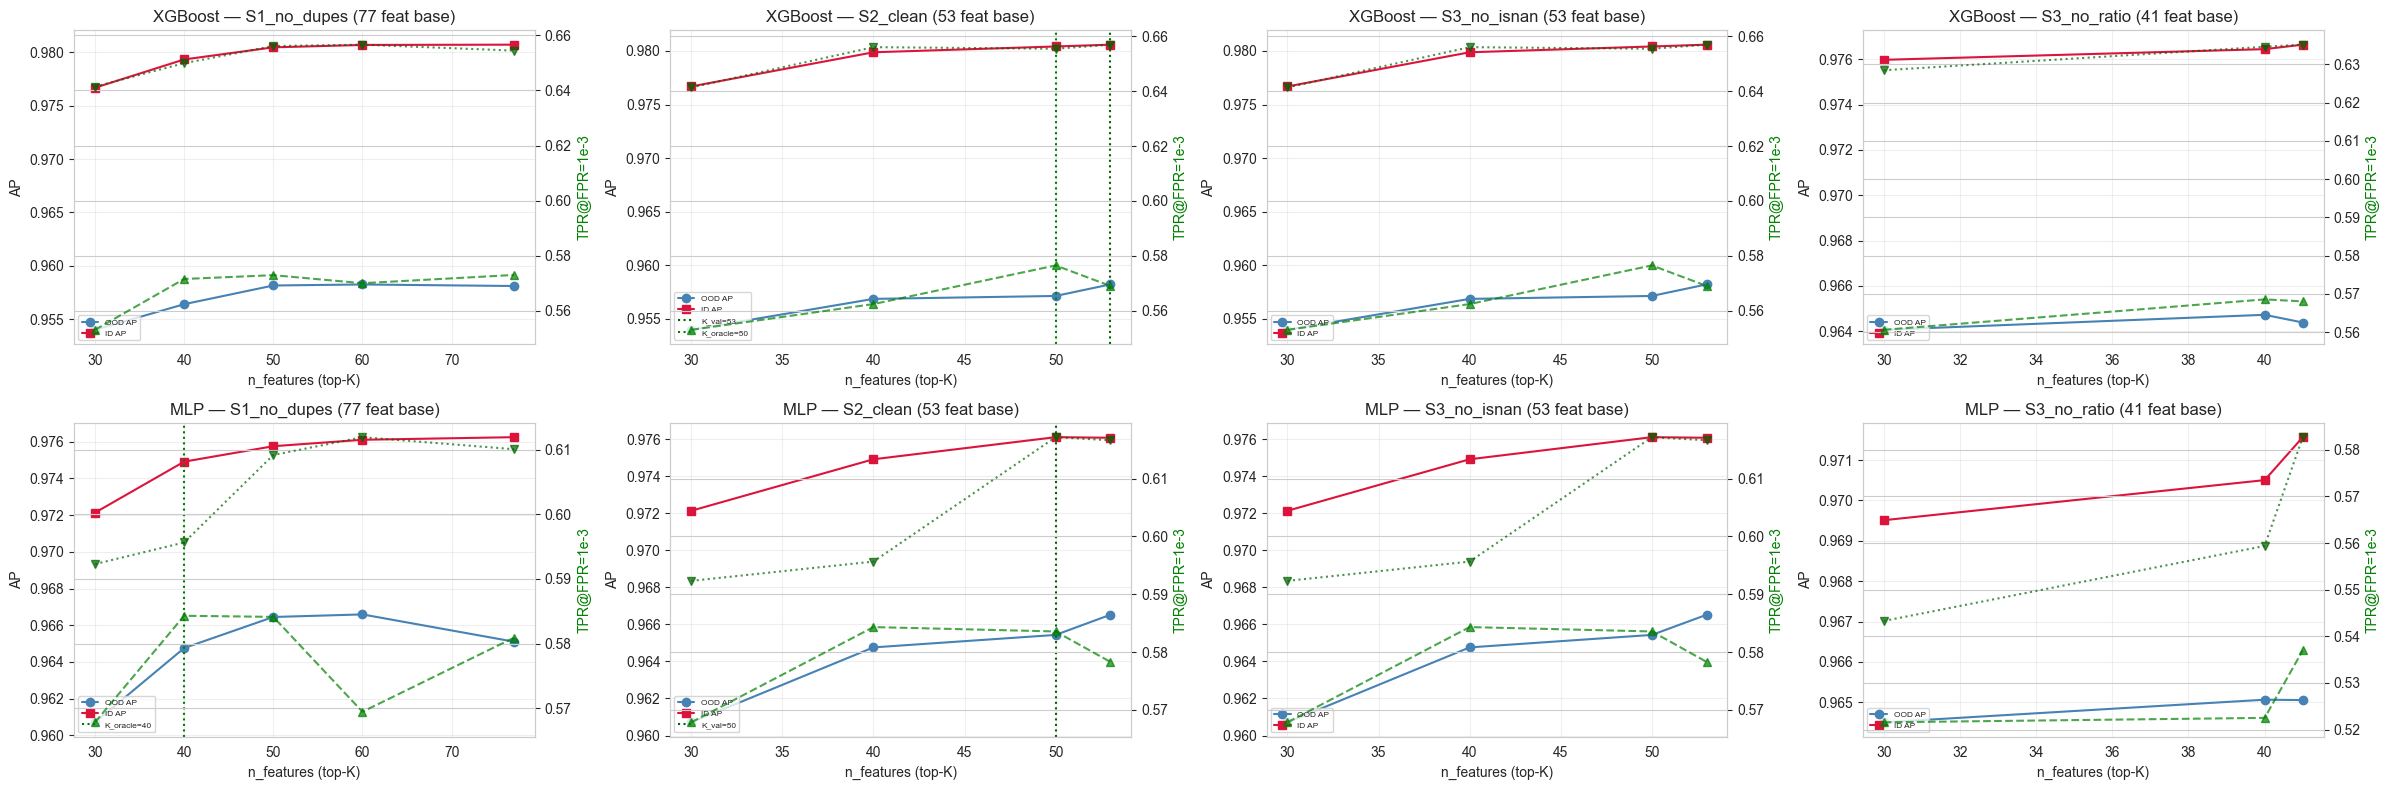

In [70]:
_fig, axes = plt.subplots(
    len(selected_models),
    len(K_SWEEP_BASES),
    figsize=(6 * len(K_SWEEP_BASES), 4 * len(selected_models)),
    squeeze=False,
)
for i, name in enumerate(selected_models):
    for j, base_label in enumerate(K_SWEEP_BASES):
        ax = axes[i, j]
        sub = ksweep_df.loc[(name, base_label)]
        ax.plot(sub.index, sub["ood_ap"], marker="o", color="steelblue", label="OOD AP")
        ax.plot(sub.index, sub["id_ap"], marker="s", color="crimson", label="ID AP")
        ax2 = ax.twinx()
        ax2.plot(
            sub.index,
            sub["ood_tpr@1e-3"],
            marker="^",
            ls="--",
            color="green",
            alpha=0.7,
            label="OOD TPR@1e-3",
        )
        ax2.plot(
            sub.index,
            sub["val_tpr@1e-3"],
            marker="v",
            ls=":",
            color="darkgreen",
            alpha=0.7,
            label="Val TPR@1e-3",
        )
        ax2.set_ylabel("TPR@FPR=1e-3", color="green")
        k_v = (
            best_k[name]["tpr_val"]["k"]
            if best_k[name]["tpr_val"]["base"] == base_label
            else None
        )
        k_o = (
            best_k[name]["tpr_oracle"]["k"]
            if best_k[name]["tpr_oracle"]["base"] == base_label
            else None
        )
        if k_v:
            ax.axvline(k_v, color="darkgreen", ls=":", label=f"K_val={k_v}")
        if k_o:
            ax.axvline(k_o, color="green", ls=":", label=f"K_oracle={k_o}")
        ax.set_title(
            f"{name} — {base_label} ({len(K_SWEEP_BASES[base_label])} feat base)"
        )
        ax.set_xlabel("n_features (top-K)")
        ax.set_ylabel("AP")
        ax.legend(loc="lower left", fontsize=6)
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "ksweep.png", dpi=140)
plt.show()

In [71]:
stage_results["S4_bestk"] = {
    "label": "S4_bestk",
    "n_features": {n: best_k[n]["tpr_val"]["k"] for n in selected_models},
    "models": {},
}
for name in selected_models:
    key = (best_k[name]["tpr_val"]["base"], best_k[name]["tpr_val"]["k"])
    r = ksweep_results[name][key]
    stage_results["S4_bestk"]["models"][name] = {
        "metrics_id": full_metrics_block(
            y_test_id, r["probs"]["test_id"], r["threshold"]
        ),
        "metrics_ood": full_metrics_block(
            y_test_ood, r["probs"]["test_ood"], r["threshold"]
        ),
        "per_family_recall_ood": r["per_family_recall_ood"],
        "threshold": r["threshold"],
        "train_s": r["train_s"],
        "latency": r["latency"],
        "probs": r["probs"],
    }

stage_table = build_stage_table(stage_results)
baseline_ood = {n: baseline_metrics[n]["metrics_ood"]["pr_auc"] for n in MODEL_REGISTRY}
baseline_tpr = {
    n: baseline_metrics[n]["metrics_ood"]["tpr@fpr=0.001"] for n in MODEL_REGISTRY
}
delta_table = stage_table.copy()
delta_table["delta_ood_ap_pp"] = delta_table.apply(
    lambda r: (r["ood_ap"] - baseline_ood[r["model"]]) * 100, axis=1
)
delta_table["delta_ood_tpr_pp"] = delta_table.apply(
    lambda r: (r["ood_tpr@1e-3"] - baseline_tpr[r["model"]]) * 100, axis=1
)

print("=== S4_bestk (val-selected base+K; test evaluated once) ===")
print(
    delta_table[delta_table["stage"] == "S4_bestk"][
        [
            "model",
            "n_features",
            "id_ap",
            "ood_ap",
            "ood_tpr@1e-3",
            "delta_ood_ap_pp",
            "delta_ood_tpr_pp",
            "single_ms",
            "size_mb",
        ]
    ]
    .round(4)
    .to_string()
)

=== S4_bestk (val-selected base+K; test evaluated once) ===
      model  n_features   id_ap  ood_ap  ood_tpr@1e-3  delta_ood_ap_pp  delta_ood_tpr_pp  single_ms  size_mb
42  XGBoost          53  0.9806  0.9582        0.5690          -0.1986           -1.8106     3.0463  11.4035
43      MLP          50  0.9761  0.9654        0.5836           0.2489            0.3645     0.5465   0.1152


In [72]:
pos_map = pd.Series(np.arange(len(cv_idx)), index=cv_idx)


def run_cv(model_name, feature_list, seed=SEED, variant="default"):
    cache_dir = CV_CACHE / f"{model_name}__{variant}"
    cache_dir.mkdir(parents=True, exist_ok=True)
    summary_path = cache_dir / "summary.csv"
    if CV_USE_SUMMARY_CACHE and not CACHE_RESET and summary_path.exists():
        df = pd.read_csv(summary_path)
        print(f"  [CV {model_name}/{variant}] loaded {len(df)} folds from cache")
        return df.set_index("fold") if "fold" in df.columns else df

    X_cv_raw = full_df.iloc[cv_idx][feature_list].astype("float32")
    y_cv = y_all[cv_idx]
    out = []
    for k in range(N_CV_SPLITS):
        fold_json = cache_dir / f"fold{k}.json"
        if CV_FOLD_RESUME and not CACHE_RESET and fold_json.exists():
            with open(fold_json) as f:
                out.append(json.load(f))
            print(f"  [CV {model_name}/{variant} fold {k}] cached")
            continue
        tr_pos = pos_map.loc[cv_folds_npz[f"fold_{k}_train"]].values
        va_pos = pos_map.loc[cv_folds_npz[f"fold_{k}_val"]].values

        X_tr = X_cv_raw.iloc[tr_pos]
        X_va = X_cv_raw.iloc[va_pos]
        y_tr = y_cv[tr_pos]
        y_va = y_cv[va_pos]

        cfg = MODEL_REGISTRY[model_name]
        if cfg["scale"]:
            sc = StandardScaler().fit(X_tr)
            X_tr = pd.DataFrame(sc.transform(X_tr), columns=feature_list)
            X_va = pd.DataFrame(sc.transform(X_va), columns=feature_list)

        model = fit_model(
            cfg["builder"](), model_name, X_tr, y_tr, X_va, y_va, seed=seed
        )
        p = predict_proba_1d(model, X_va)
        out.append(
            {
                "fold": k,
                "val_ap": average_precision_score(y_va, p),
                "val_tpr@1e-3": tpr_at_fpr(y_va, p, TARGET_FPR),
            }
        )
        print(
            f"  [{model_name} | {len(feature_list)} feat | fold {k}] "
            f"AP={out[-1]['val_ap']:.4f} | TPR@1e-3={out[-1]['val_tpr@1e-3']:.4f}"
        )
        if CV_FOLD_RESUME:
            with open(fold_json, "w") as f:
                json.dump(out[-1], f, indent=2)
    df = pd.DataFrame(out).set_index("fold")
    if CV_USE_SUMMARY_CACHE:
        df.to_csv(summary_path)
    return df


cv_results = {}
for name in selected_models:
    print(
        f"\n{'=' * 60}\nCV: {name} baseline ({len(PRETRAINED_FEAT)} feat)\n{'=' * 60}"
    )
    cv_results[(name, "baseline")] = run_cv(name, PRETRAINED_FEAT, variant="baseline")
    print(
        f"\n{'=' * 60}\nCV: {name} optimized ({len(optimized_features[name])} feat)\n{'=' * 60}"
    )
    cv_results[(name, "optimized")] = run_cv(name, optimized_features[name], variant="optimized")

cv_rows = []
for name in selected_models:
    base = cv_results[(name, "baseline")]
    opt = cv_results[(name, "optimized")]
    d_ap_pp = (opt["val_ap"].values - base["val_ap"].values).mean() * 100
    d_tpr_pp = (opt["val_tpr@1e-3"].values - base["val_tpr@1e-3"].values).mean() * 100
    try:
        _, p_ap = wilcoxon(base["val_ap"].values, opt["val_ap"].values)
        _, p_tpr = wilcoxon(base["val_tpr@1e-3"].values, opt["val_tpr@1e-3"].values)
    except ValueError:
        p_ap = p_tpr = float("nan")
    cv_rows.append(
        {
            "model": name,
            "baseline_n": len(PRETRAINED_FEAT),
            "optimized_n": len(optimized_features[name]),
            "baseline_ap_mean": base["val_ap"].mean(),
            "baseline_ap_std": base["val_ap"].std(),
            "optimized_ap_mean": opt["val_ap"].mean(),
            "optimized_ap_std": opt["val_ap"].std(),
            "delta_ap_pp": d_ap_pp,
            "p_ap_wilcoxon": p_ap,
            "baseline_tpr_mean": base["val_tpr@1e-3"].mean(),
            "baseline_tpr_std": base["val_tpr@1e-3"].std(),
            "optimized_tpr_mean": opt["val_tpr@1e-3"].mean(),
            "optimized_tpr_std": opt["val_tpr@1e-3"].std(),
            "delta_tpr_pp": d_tpr_pp,
            "p_tpr_wilcoxon": p_tpr,
        }
    )

cv_summary = pd.DataFrame(cv_rows).set_index("model")
print("\n=== CV summary (5-fold family-aware; same folds e2e_models.ipynb) ===")
print(cv_summary.round(4).to_string())
print(
    "\nWilcoxon n=5 → min achievable p = 0.0625; use |Δ| for gating, report p for transparency."
)


CV: XGBoost baseline (130 feat)
  [XGBoost | 130 feat | fold 0] AP=0.8644 | TPR@1e-3=0.3188
  [XGBoost | 130 feat | fold 1] AP=0.9108 | TPR@1e-3=0.3995
  [XGBoost | 130 feat | fold 2] AP=0.9410 | TPR@1e-3=0.5181
  [XGBoost | 130 feat | fold 3] AP=0.8712 | TPR@1e-3=0.3351
  [XGBoost | 130 feat | fold 4] AP=0.9727 | TPR@1e-3=0.6061

CV: XGBoost optimized (53 feat)
  [XGBoost | 53 feat | fold 0] AP=0.8657 | TPR@1e-3=0.2920
  [XGBoost | 53 feat | fold 1] AP=0.9104 | TPR@1e-3=0.3998
  [XGBoost | 53 feat | fold 2] AP=0.9405 | TPR@1e-3=0.5072
  [XGBoost | 53 feat | fold 3] AP=0.8717 | TPR@1e-3=0.3291
  [XGBoost | 53 feat | fold 4] AP=0.9728 | TPR@1e-3=0.6219

CV: MLP baseline (130 feat)
  [MLP | 130 feat | fold 0] AP=0.8552 | TPR@1e-3=0.3778
  [MLP | 130 feat | fold 1] AP=0.9121 | TPR@1e-3=0.3817
  [MLP | 130 feat | fold 2] AP=0.9410 | TPR@1e-3=0.5435
  [MLP | 130 feat | fold 3] AP=0.8536 | TPR@1e-3=0.2464
  [MLP | 130 feat | fold 4] AP=0.9624 | TPR@1e-3=0.6498

CV: MLP optimized (50 feat)
 

### Section 6. Final summary and artifacts

Viability gate (pre-registered in config; all must hold):
- `gate_tpr`       — honest Δ OOD TPR@fpr=1e-3 ≥ −0.5 pp
- `gate_reduction` — reduction ≥ 20 %
- `gate_cv_ap`     — CV Δ AP ≥ −0.5 pp
- `gate_cv_tpr`    — CV Δ TPR@fpr=1e-3 ≥ −0.5 pp

If viable, saved to `models/`:
- `optimized_features.json` — val-selected feature list per model
- `{name}_optimized.pkl` — val-selected model (same features as artifact)
- `{name}_optimized_cal.pkl` — Isotonic calibrator (val-fit) *(if section 7 is run)*
- `model_artifact_v2.json` — primary = honest (val-selected); oracle stored as `oracle_reference` for transparency
- `optimization_summary.csv` — TPR/FPR/AP/Brier/latency for baseline, honest, oracle
- `optimization_per_family_recall.csv` — per-family baseline vs optimized recall delta

In [73]:
final_rows = []
for name in selected_models:
    key_val = (best_k[name]["tpr_val"]["base"], best_k[name]["tpr_val"]["k"])
    key_oracle = (best_k[name]["tpr_oracle"]["base"], best_k[name]["tpr_oracle"]["k"])
    r_val = ksweep_results[name][key_val]
    r_oracle = ksweep_results[name][key_oracle]
    base = baseline_metrics[name]
    cvr = cv_summary.loc[name]

    k_opt = key_val[1]
    delta_tpr_pp = (r_val["ood_tpr@1e-3"] - base["metrics_ood"]["tpr@fpr=0.001"]) * 100
    delta_tpr_oracle_pp = (
        r_oracle["ood_tpr@1e-3"] - base["metrics_ood"]["tpr@fpr=0.001"]
    ) * 100
    delta_ap_pp = (r_val["ood_ap"] - base["metrics_ood"]["pr_auc"]) * 100
    reduction_pct = (1 - k_opt / len(PRETRAINED_FEAT)) * 100

    gate_tpr = delta_tpr_pp >= -VIABILITY_MAX_DEGRADATION_PP
    gate_reduction = reduction_pct >= VIABILITY_MIN_REDUCTION_PCT
    gate_cv_ap = cvr["delta_ap_pp"] >= -VIABILITY_MAX_DEGRADATION_PP
    gate_cv_tpr = cvr["delta_tpr_pp"] >= -VIABILITY_MAX_DEGRADATION_PP
    viable = gate_tpr and gate_reduction and gate_cv_ap and gate_cv_tpr

    m_od = full_metrics_block(
        y_test_ood, r_val["probs"]["test_ood"], r_val["threshold"]
    )
    m_id = full_metrics_block(y_test_id, r_val["probs"]["test_id"], r_val["threshold"])

    final_rows.append(
        {
            "model": name,
            "selected_base": key_val[0],
            "n_features_baseline": len(PRETRAINED_FEAT),
            "n_features_optimized": k_opt,
            "reduction_pct": reduction_pct,
            # honest (val-selected K, test evaluated once) — primary
            "honest_ood_tpr@1e-3": m_od["tpr@fpr=0.001"],
            "honest_ood_pr_auc": m_od["pr_auc"],
            "honest_delta_ood_tpr_pp": delta_tpr_pp,
            "honest_delta_ood_ap_pp": delta_ap_pp,
            # oracle (best over all bases × K on test) — upper bound, not deployment-realistic
            "oracle_base": best_k[name]["tpr_oracle"]["base"],
            "oracle_k": best_k[name]["tpr_oracle"]["k"],
            "oracle_ood_tpr@1e-3": r_oracle["ood_tpr@1e-3"],
            "oracle_delta_ood_tpr_pp": delta_tpr_oracle_pp,
            "selection_bias_pp": delta_tpr_oracle_pp - delta_tpr_pp,
            # rest
            "baseline_ood_pr_auc": base["metrics_ood"]["pr_auc"],
            "baseline_ood_tpr@1e-3": base["metrics_ood"]["tpr@fpr=0.001"],
            "baseline_ood_fpr": base["metrics_ood"]["fpr"],
            "baseline_ood_prec@prev=1e-4": base["metrics_ood"]["prec@prev=0.0001"],
            "baseline_ood_brier": base["metrics_ood"]["brier"],
            "baseline_single_ms": base["latency"]["single_ms"],
            "baseline_size_mb": base["latency"]["size_mb"],
            "optimized_id_pr_auc": m_id["pr_auc"],
            "optimized_ood_fpr": m_od["fpr"],
            "optimized_ood_prec@prev=1e-4": m_od["prec@prev=0.0001"],
            "optimized_ood_brier": m_od["brier"],
            "optimized_single_ms": r_val["latency"]["single_ms"],
            "optimized_size_mb": r_val["latency"]["size_mb"],
            "delta_single_ms_pct": (
                r_val["latency"]["single_ms"] / base["latency"]["single_ms"] - 1
            )
            * 100,
            "delta_size_mb_pct": (
                r_val["latency"]["size_mb"] / base["latency"]["size_mb"] - 1
            )
            * 100,
            "cv_baseline_ap_mean": cvr["baseline_ap_mean"],
            "cv_baseline_ap_std": cvr["baseline_ap_std"],
            "cv_optimized_ap_mean": cvr["optimized_ap_mean"],
            "cv_optimized_ap_std": cvr["optimized_ap_std"],
            "cv_delta_ap_pp": cvr["delta_ap_pp"],
            "cv_delta_tpr_pp": cvr["delta_tpr_pp"],
            "cv_p_ap_wilcoxon": cvr["p_ap_wilcoxon"],
            "cv_p_tpr_wilcoxon": cvr["p_tpr_wilcoxon"],
            "gate_tpr_ok": bool(gate_tpr),
            "gate_reduction_ok": bool(gate_reduction),
            "gate_cv_ap_ok": bool(gate_cv_ap),
            "gate_cv_tpr_ok": bool(gate_cv_tpr),
            "viable": bool(viable),
            "convergence_gap_pp": diag_mlp["gap_pp"] if name == "MLP" else float("nan"),
            "convergence_plateau_epoch": diag_mlp["epochs_run"]
            if name == "MLP"
            else float("nan"),
        }
    )

final_df = pd.DataFrame(final_rows).set_index("model")
final_df.to_csv(PATHS["models_dir"] / "optimization_summary.csv")

print("=== Final summary: baseline vs optimized ===")
show_cols = [
    "selected_base",
    "n_features_baseline",
    "n_features_optimized",
    "reduction_pct",
    "baseline_ood_tpr@1e-3",
    "honest_ood_tpr@1e-3",
    "honest_delta_ood_tpr_pp",
    "oracle_base",
    "oracle_k",
    "oracle_ood_tpr@1e-3",
    "oracle_delta_ood_tpr_pp",
    "selection_bias_pp",
    "baseline_ood_pr_auc",
    "honest_ood_pr_auc",
    "honest_delta_ood_ap_pp",
    "baseline_single_ms",
    "optimized_single_ms",
    "delta_single_ms_pct",
    "baseline_size_mb",
    "optimized_size_mb",
    "delta_size_mb_pct",
    "cv_delta_ap_pp",
    "cv_delta_tpr_pp",
    "viable",
]
print(final_df[show_cols].round(4).to_string())

viable_models = final_df[final_df["viable"]].index.tolist()
print(f"\nViable: {viable_models}")

viable_models = final_df[final_df["viable"]].index.tolist()
print(f"\nViable: {viable_models}")

if viable_models:
    # 1. optimized_features.json — val-selected (honest) features
    to_save = {n: optimized_features[n] for n in viable_models}
    with open(PATHS["models_dir"] / "optimized_features.json", "w") as f:
        json.dump(to_save, f, indent=2, ensure_ascii=False)
    print(f"Saved optimized_features.json: { {n: len(v) for n, v in to_save.items()} }")

    # 2. *_optimized.pkl — val-selected models (same features as artifact_v2)
    for name in viable_models:
        key_val = (best_k[name]["tpr_val"]["base"], best_k[name]["tpr_val"]["k"])
        r_val = ksweep_results[name][key_val]
        joblib.dump(r_val["model"], PATHS["models_dir"] / f"{name}_optimized.pkl")
    print("Saved *_optimized.pkl")

    # 3. artifact_v2 — primary = r_val (honest); oracle only as reference
    artifact_v2 = json.loads(json.dumps(artifact))
    artifact_v2["feature_set_version"] = "reduced"
    artifact_v2.setdefault("reduced_models", {})
    artifact_v2["convergence_diagnostic"] = {
        k: v for k, v in diag_mlp.items() if k not in ("aps", "losses")
    }

    for name in viable_models:
        key_val = (best_k[name]["tpr_val"]["base"], best_k[name]["tpr_val"]["k"])
        key_oracle = (
            best_k[name]["tpr_oracle"]["base"],
            best_k[name]["tpr_oracle"]["k"],
        )
        r_val = ksweep_results[name][key_val]
        r_oracle = ksweep_results[name][key_oracle]

        m_od = full_metrics_block(
            y_test_ood, r_val["probs"]["test_ood"], r_val["threshold"]
        )
        m_id = full_metrics_block(
            y_test_id, r_val["probs"]["test_id"], r_val["threshold"]
        )

        artifact_v2["reduced_models"][name] = {
            "base": key_val[0],
            "features": r_val["features"],
            "n_features": int(key_val[1]),
            "threshold": float(r_val["threshold"]),
            "metrics_id": {kk: float(vv) for kk, vv in m_id.items()},
            "metrics_ood": {kk: float(vv) for kk, vv in m_od.items()},
            "per_family_recall_ood": {
                kk: float(vv) for kk, vv in r_val["per_family_recall_ood"].items()
            },
            "latency": {kk: float(vv) for kk, vv in r_val["latency"].items()},
            "cv_summary": {
                kk: (bool(vv) if isinstance(vv, (bool, np.bool_)) else float(vv))
                for kk, vv in cv_summary.loc[name].items()
            },
            # oracle = reference only; NOT a deployable config
            "oracle_reference": {
                "base": key_oracle[0],
                "n_features": int(key_oracle[1]),
                "ood_tpr@1e-3": float(r_oracle["ood_tpr@1e-3"]),
            },
        }

    with open(PATHS["models_dir"] / "model_artifact_v2.json", "w") as f:
        json.dump(artifact_v2, f, indent=2, default=float)
    print("Saved model_artifact_v2.json")

    # 4. per-family recall delta — honest config
    fam_rows = []
    for name in viable_models:
        base_fam = stage_results["S0_baseline"]["models"][name]["per_family_recall_ood"]
        key_val = (best_k[name]["tpr_val"]["base"], best_k[name]["tpr_val"]["k"])
        opt_fam = ksweep_results[name][key_val]["per_family_recall_ood"]
        for fam in sorted(set(base_fam) | set(opt_fam)):
            b = base_fam.get(fam, float("nan"))
            o = opt_fam.get(fam, float("nan"))
            fam_rows.append(
                {
                    "model": name,
                    "family": fam,
                    "baseline_recall": b,
                    "optimized_recall": o,
                    "delta_pp": (o - b) * 100,
                }
            )
    pd.DataFrame(fam_rows).to_csv(
        PATHS["models_dir"] / "optimization_per_family_recall.csv", index=False
    )
    print("Saved optimization_per_family_recall.csv")
else:
    print("\nNo model met viability criteria — nothing saved.")

=== Final summary: baseline vs optimized ===
        selected_base  n_features_baseline  n_features_optimized  reduction_pct  baseline_ood_tpr@1e-3  honest_ood_tpr@1e-3  honest_delta_ood_tpr_pp  oracle_base  oracle_k  oracle_ood_tpr@1e-3  oracle_delta_ood_tpr_pp  selection_bias_pp  baseline_ood_pr_auc  honest_ood_pr_auc  honest_delta_ood_ap_pp  baseline_single_ms  optimized_single_ms  delta_single_ms_pct  baseline_size_mb  optimized_size_mb  delta_size_mb_pct  cv_delta_ap_pp  cv_delta_tpr_pp  viable
model                                                                                                                                                                                                                                                                                                                                                                                                                                                                      
XGBoost      S2_clean              

### Section 7. Calibration (Isotonic on val, evaluated on test_ood)

Brier is the only metric affected by calibration; threshold-based metrics (TPR/FPR/AP) are invariant under monotone transforms.
Baseline uses `{name}_cal.pkl` from `models.ipynb`; optimized uses fresh Isotonic fit on `probs["val"]`.

In [74]:
key_val = {
    n: (best_k[n]["tpr_val"]["base"], best_k[n]["tpr_val"]["k"])
    for n in selected_models
}

cal_rows = []
for name in selected_models:
    # Baseline: use existing Isotonic from models.ipynb
    base_raw_ood = baseline_probs["test_ood"][name]
    base_brier_raw = brier_score_loss(y_test_ood, base_raw_ood)
    if name in calibrators:
        base_brier_cal = brier_score_loss(
            y_test_ood, calibrators[name].predict(base_raw_ood)
        )
    else:
        base_brier_cal = float("nan")

    # Optimized: fit Isotonic on val, evaluate on test_ood
    r_val = ksweep_results[name][key_val[name]]
    p_val = r_val["probs"]["val"]
    p_ood = r_val["probs"]["test_ood"]
    iso = IsotonicRegression(out_of_bounds="clip").fit(p_val, y_val)
    opt_brier_raw = brier_score_loss(y_test_ood, p_ood)
    opt_brier_cal = brier_score_loss(y_test_ood, iso.predict(p_ood))

    cal_rows.append(
        {
            "model": name,
            "baseline_brier_raw": base_brier_raw,
            "baseline_brier_cal": base_brier_cal,
            "optimized_brier_raw": opt_brier_raw,
            "optimized_brier_cal": opt_brier_cal,
            "delta_brier_raw": opt_brier_raw - base_brier_raw,
            "delta_brier_cal": opt_brier_cal - base_brier_cal,
        }
    )

    if name in viable_models:
        joblib.dump(iso, PATHS["models_dir"] / f"{name}_optimized_cal.pkl")

cal_df = pd.DataFrame(cal_rows).set_index("model")
print("=== Calibration diagnostics (test_ood) ===")
print(cal_df.round(5).to_string())

=== Calibration diagnostics (test_ood) ===
         baseline_brier_raw  baseline_brier_cal  optimized_brier_raw  optimized_brier_cal  delta_brier_raw  delta_brier_cal
model                                                                                                                      
XGBoost             0.09231             0.09243              0.09461              0.09463          0.00230          0.00221
MLP                 0.08709             0.08624              0.08285              0.08189         -0.00424         -0.00435


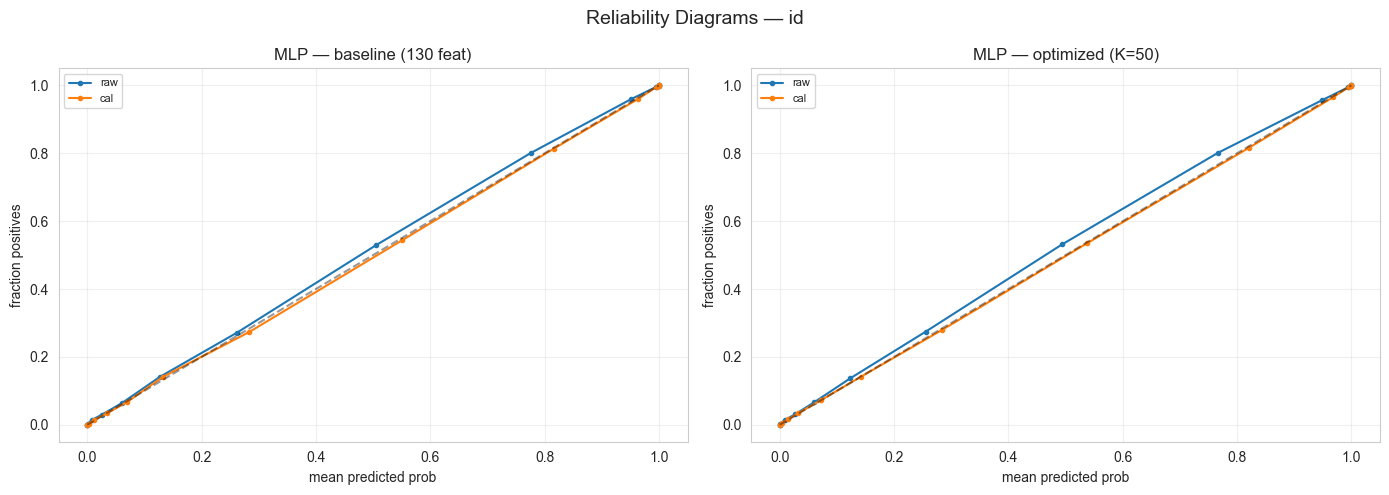

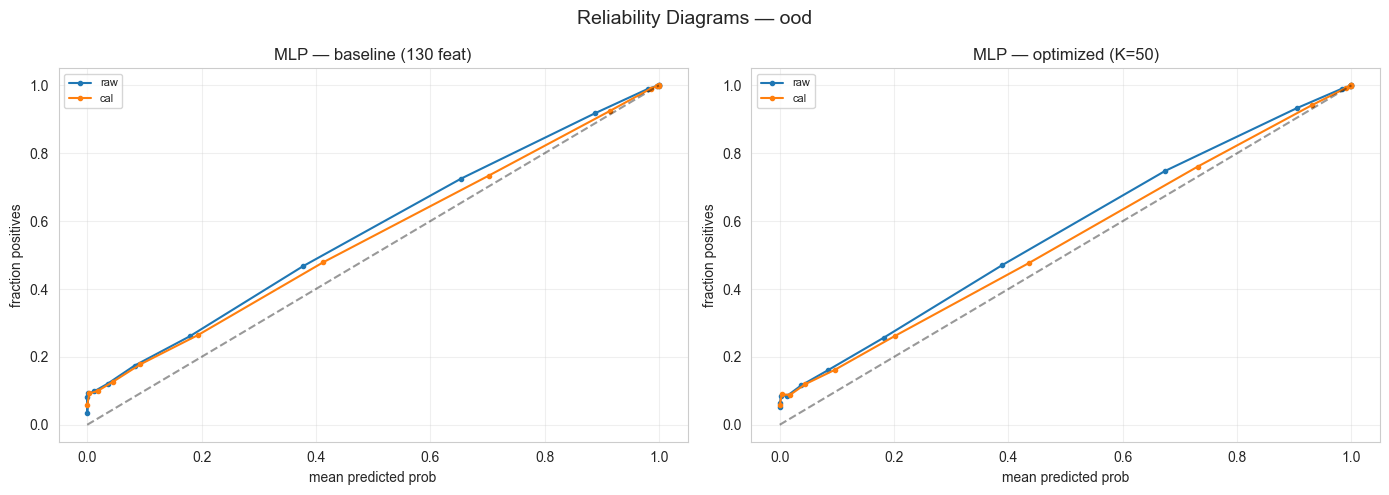

In [85]:
key_val = {
    n: (best_k[n]["tpr_val"]["base"], best_k[n]["tpr_val"]["k"]) for n in viable_models
}

for split_label, y_true, probs_key in [
    ("id", y_test_id, "test_id"),
    ("ood", y_test_ood, "test_ood"),
]:
    n_models = len(viable_models)
    _fig, axes = plt.subplots(n_models, 2, figsize=(14, 5 * n_models), squeeze=False)
    
    for row, name in zip(axes, viable_models):
        ax_base, ax_opt = row
        r_val = ksweep_results[name][key_val[name]]
        k_label = f"K={key_val[name][1]}"

        # Baseline
        p_base = baseline_probs[probs_key][name]
        for label, p in [
            ("raw", p_base),
            ("cal", calibrators[name].predict(p_base) if name in calibrators else None),
        ]:
            if p is None:
                continue
            frac_pos, mean_pred = calibration_curve(
                y_true, p, n_bins=15, strategy="quantile"
            )
            ax_base.plot(mean_pred, frac_pos, marker=".", label=label)
        ax_base.plot([0, 1], [0, 1], "k--", alpha=0.4)
        ax_base.set_title(f"{name} — baseline (130 feat)")
        ax_base.set_xlabel("mean predicted prob")
        ax_base.set_ylabel("fraction positives")
        ax_base.legend(fontsize=8)
        ax_base.grid(alpha=0.3)

        # Optimized
        p_opt = r_val["probs"][probs_key]
        iso_opt = IsotonicRegression(out_of_bounds="clip").fit(
            r_val["probs"]["val"], y_val
        )
        for label, p in [
            ("raw", p_opt),
            ("cal", iso_opt.predict(p_opt)),
        ]:
            frac_pos, mean_pred = calibration_curve(
                y_true, p, n_bins=15, strategy="quantile"
            )
            ax_opt.plot(mean_pred, frac_pos, marker=".", label=label)
        ax_opt.plot([0, 1], [0, 1], "k--", alpha=0.4)
        ax_opt.set_title(f"{name} — optimized ({k_label})")
        ax_opt.set_xlabel("mean predicted prob")
        ax_opt.set_ylabel("fraction positives")
        ax_opt.legend(fontsize=8)
        ax_opt.grid(alpha=0.3)

    plt.suptitle(f"Reliability Diagrams — {split_label}", fontsize=14)
    plt.tight_layout()
    plt.savefig(PATHS["plots_dir"] / f"reliability_opt_{split_label}.png", dpi=140)
    plt.show()

In [76]:
# Update artifacts
final_df_cal = final_df.join(cal_df)
final_df_cal.to_csv(PATHS["models_dir"] / "optimization_summary.csv")

with open(PATHS["models_dir"] / "model_artifact_v2.json") as f:
    artifact_v2 = json.load(f)
for name in viable_models:
    row = cal_df.loc[name]
    artifact_v2["reduced_models"][name]["brier_raw"] = float(row["optimized_brier_raw"])
    artifact_v2["reduced_models"][name]["brier_cal"] = float(row["optimized_brier_cal"])
    artifact_v2["reduced_models"][name]["calibrator_path"] = (
        f"models/{name}_optimized_cal.pkl"
    )
with open(PATHS["models_dir"] / "model_artifact_v2.json", "w") as f:
    json.dump(artifact_v2, f, indent=2, default=float)